# CAMS EAC4 EDA — Việt Nam, native GRIB grid

Pipeline dùng `VARIABLES`, lịch giờ và phạm vi từ downloader. Raw GRIB chỉ được đọc.
Các kết quả và finding được tính khi chạy notebook; không có kết luận mẫu hard-code.

**Chạy:** `python -m pip install -r requirements.txt`, chọn kernel của môi trường
đó và Run All. Không cần API token để EDA dữ liệu đã có. CLI tương đương: `python -m src.eda`.

**Key assumptions:** tọa độ time là UTC; regional mean dùng cos(latitude) trên
bounding box gồm cả biển/đất ngoài Việt Nam, không có country mask. Không regrid,
interpolate, impute hay xóa outlier. Percentile summary chính xác; ECDF dùng mẫu uniform
seed cố định. Trend chỉ dùng annual grid mean đủ coverage. Xem unit audit và chất lượng trước
khi diễn giải các biến dẫn xuất. Cache là working storage EDA có thể dựng lại, không phải raw/Bronze.


## 0. Setup

**Question:** Notebook đang chạy từ project nào và môi trường nào?

**Why this analysis:** Giữ đường dẫn và package versions rõ ràng để có thể chạy lại.

In [1]:
import os
import sys
from pathlib import Path
from importlib.metadata import version

import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / 'src/download_cams_dataset.py').is_file()), None)
if PROJECT is None:
    raise RuntimeError('Run this notebook from the project root or notebooks directory')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from src.download_cams_dataset import VARIABLES, TIMES, VIETNAM_AREA, DATASET, DEFAULT_DATA_ROOT
from src.eda import EDAConfig, EDARun

def show_figures(paths):
    if not paths:
        display(Markdown('skipped: required variable not available, hoặc không đủ quan sát hợp lệ'))
    for path in paths:
        display(Image(filename=str(path)))

display(pd.DataFrame({'package': [p for p in ('xarray', 'cfgrib', 'eccodes', 'numpy', 'pandas', 'matplotlib', 'scipy', 'dask')],
                      'version': [version(p) for p in ('xarray', 'cfgrib', 'eccodes', 'numpy', 'pandas', 'matplotlib', 'scipy', 'dask')]}))
display(Markdown(f'**Finding:** Project: `{PROJECT}`; Python: `{sys.version.split()[0]}`.'))


,package,version
0,xarray,2026.7.0
1,cfgrib,0.9.15.1
2,eccodes,2.48.0
3,numpy,2.5.3
4,pandas,3.0.5
5,matplotlib,3.11.2
6,scipy,1.18.1
7,dask,2026.8.0


**Finding:** Project: `D:\Data\Learning\TLCN\Code\test_data`; Python: `3.12.10`.

## 1. Project configuration

**Question:** Giai đoạn, biến và sampling rule nào sẽ được dùng?

**Why this analysis:** Cấu hình tập trung để notebook tự kích hoạt khi đủ các file downloader.

In [2]:
# Default: all downloader variables, 2003–2025. Environment overrides support validation.
config = EDAConfig(
    data_root=Path(os.environ.get('CAMS_EDA_DATA_ROOT', str(DEFAULT_DATA_ROOT))),
    report_root=Path(os.environ.get('CAMS_EDA_REPORT_ROOT', str(PROJECT / 'reports'))),
    cache_root=Path(os.environ['CAMS_EDA_CACHE_ROOT']) if os.environ.get('CAMS_EDA_CACHE_ROOT') else None,
    chunk_time=2048,
    sample_size=50_000,
    seed=42,
    minimum_annual_coverage=0.95,
    rebuild_cache=False,  # True rebuilds disposable EDA buffers/index/header summaries.
    filter_by_keys={},  # e.g. {'pm1': {'paramId': ...}} if metadata exposes ambiguous hypercubes.
)
run = EDARun(config)
import logging
config.report_root.mkdir(parents=True, exist_ok=True)
logging.basicConfig(filename=config.report_root / 'execution.log', encoding='utf-8',
                    level=logging.INFO, format='%(asctime)s | %(message)s', force=True)
display(Markdown(f'**Finding:** `{DATASET}`, {config.start_year}–{config.end_year}; '
                 f'{len(config.expected_time):,} expected timestamps, cadence {config.cadence}; '
                 f'area {VIETNAM_AREA}; seed={config.seed}.'))
display(pd.DataFrame(VARIABLES.items(), columns=['short_name', 'source_variable_name']))


**Finding:** `cams-global-reanalysis-eac4`, 2003–2025; 67,208 expected timestamps, cadence 0 days 03:00:00; area (24.0, 102.0, 8.0, 110.0); seed=42.

,short_name,source_variable_name
0,pm1,particulate_matter_1um
1,pm2p5,particulate_matter_2.5um
2,pm10,particulate_matter_10um
3,u10,10m_u_component_of_wind
4,v10,10m_v_component_of_wind
5,t2m,2m_temperature
6,d2m,2m_dewpoint_temperature
7,sp,surface_pressure
8,mslp,mean_sea_level_pressure
9,aod550,total_aerosol_optical_depth_550nm


## 2. Discover GRIB files

**Question:** Biến nào có file, thiếu file hoặc có file không thuộc VARIABLES?

**Why this analysis:** Không làm crash bản mẫu chỉ có PM1; không tự chọn giữa các file không rõ ràng.

In [3]:
display(run.discover()[['short_name', 'source_variable_name', 'status', 'filename', 'file_size']])
display(run.extras)
display(Markdown('**Finding:** ' + ', '.join(
    f'{status}={count}' for status, count in run.inventory.status.value_counts().items())))


,short_name,source_variable_name,status,filename,file_size
0,pm1,particulate_matter_1um,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472
1,pm2p5,particulate_matter_2.5um,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472
2,pm10,particulate_matter_10um,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472
3,u10,10m_u_component_of_wind,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39919744
4,v10,10m_v_component_of_wind,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136
5,t2m,2m_temperature,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136
6,d2m,2m_dewpoint_temperature,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136
7,sp,surface_pressure,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136
8,mslp,mean_sea_level_pressure,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136
9,aod550,total_aerosol_optical_depth_550nm,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472


,filename,file_size,reason


**Finding:** available=14

## 3. Dataset inventory

**Question:** Metadata thực tế nói gì về unit, time axis và native grid?

**Why this analysis:** Đọc GRIB bằng cfgrib/ecCodes; file trên 65.536 timestamp vẫn được kiểm tra toàn bộ.

In [4]:
inventory, consistency_report = run.inspect()
display(inventory)


,short_name,source_variable_name,status,filename,file_size,notes,grib_variable_name,long_name,unit,dimensions,...,start_time,end_time,time_frequency,lat_min,lat_max,lon_min,lon_max,lat_resolution,lon_resolution,dtype
0,pm1,particulate_matter_1um,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472,Selected GRIB messages=67208; hypercubes=1,pm1,Particulate matter d <= 1 um,kg m**-3,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
1,pm2p5,particulate_matter_2.5um,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472,Selected GRIB messages=67208; hypercubes=1,pm2p5,Particulate matter d <= 2.5 um,kg m**-3,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
2,pm10,particulate_matter_10um,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472,Selected GRIB messages=67208; hypercubes=1,pm10,Particulate matter d <= 10 um,kg m**-3,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
3,u10,10m_u_component_of_wind,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39919744,Selected GRIB messages=67432; hypercubes=1,10u,10 metre U wind component,m s**-1,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
4,v10,10m_v_component_of_wind,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136,Selected GRIB messages=67208; hypercubes=1,10v,10 metre V wind component,m s**-1,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
5,t2m,2m_temperature,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136,Selected GRIB messages=67208; hypercubes=1,2t,2 metre temperature,K,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
6,d2m,2m_dewpoint_temperature,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136,Selected GRIB messages=67208; hypercubes=1,2d,2 metre dewpoint temperature,K,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
7,sp,surface_pressure,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136,Selected GRIB messages=67208; hypercubes=1,sp,Surface pressure,Pa,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
8,mslp,mean_sea_level_pressure,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,39787136,Selected GRIB messages=67208; hypercubes=1,msl,Mean sea level pressure,Pa,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32
9,aod550,total_aerosol_optical_depth_550nm,available,D:\Data\Learning\TLCN\Code\test_data\data\CAMS...,56051472,Selected GRIB messages=67208; hypercubes=1,aod550,Total Aerosol Optical Depth at 550nm,~,"{'time': 67208, 'latitude': 22, 'longitude': 11}",...,2003-01-01 00:00:00,2025-12-31 21:00:00,0 days 03:00:00,8.25,24.0,102.0,109.5,0.75,0.75,float32


In [5]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('inventory'))))

**Finding:**

Đọc được 14/14 biến khai báo: pm1, pm2p5, pm10, u10, v10, t2m, d2m, sp, mslp, aod550, co_column, no2_column, so2_column, o3_column. Thiếu: không có. Giai đoạn quan sát: 2003-01-01 00:00:00 — 2025-12-31 21:00:00 UTC.

Grid của pm1: 22 × 11 điểm, bước latitude 0.75°, longitude 0.75°; 67,208 timestamp.

## 4. Grid/time consistency

**Question:** Các biến có cùng tọa độ, thứ tự grid và timestamp hay không?

**Why this analysis:** Tránh align/regrid ngầm làm sai kiểm tra vật lý hoặc relationship.

In [6]:
display(consistency_report)
display(Markdown('Tham khảo `reports/tables/consistency.csv` để xem missing examples, '
                 'duplicate GRIB examples, extent/resolution và khác biệt với reference. '
                 'Missing count gồm đầu/cuối giai đoạn cấu hình; internal missing chỉ trong giai đoạn quan sát.'))


,variable,same_time_grid,same_spatial_grid,missing_timestamps,internal_missing_timestamps,missing_examples,missing_ranges,duplicate_timestamps,duplicate_messages,identical_duplicate_messages,...,irregular_intervals,off_schedule_timestamps,latitude_order,lat_resolution,lon_resolution,latitude_values,longitude_values,notes,reference_variable,hypercubes_opened
0,pm1,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
1,pm2p5,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
2,pm10,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
3,u10,True,True,0,0,,,0,224,224,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
4,v10,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
5,t2m,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
6,d2m,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
7,sp,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
8,mslp,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1
9,aod550,True,True,0,0,,,0,0,0,...,0,0,descending,0.75,0.75,"[24.0, 23.25, 22.5, 21.75, 21.0, 20.25, 19.5, ...","[102.0, 102.75, 103.5, 104.25, 105.0, 105.75, ...",matches reference coordinates,pm1,1


Tham khảo `reports/tables/consistency.csv` để xem missing examples, duplicate GRIB examples, extent/resolution và khác biệt với reference. Missing count gồm đầu/cuối giai đoạn cấu hình; internal missing chỉ trong giai đoạn quan sát.

In [7]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('quality'))))

**Finding:**

So với pm1, 14/14 biến cùng trục thời gian và 14/14 biến cùng grid theo đúng thứ tự tọa độ. Tổng timestamp thiếu so với giai đoạn cấu hình (cộng qua biến): 0; message trùng: 224.

Các message trùng: 224 bản có cùng decoded values/grid với bản đầu, 0 bản xung đột. Bản giống nhau dùng representation đầu của cfgrib có audit rõ ràng; bản xung đột không được dùng cho analysis liên biến.

## 5. Unit normalization

**Question:** Có thể chuyển unit nào và derive wind/RH nào từ metadata xác nhận?

**Why this analysis:** Không coi AOD là PM hoặc total-column variables là surface concentration.

In [8]:
display(run.normalize())
display(pd.DataFrame(run.statuses))
from src.eda.transformations import RH_FORMULA, RH_SOURCE
display(Markdown(f'RH formula: {RH_FORMULA}\n\n[WMO reference]({RH_SOURCE})'))
display(Markdown('**Finding:** Các conversion ở bảng trên áp dụng trên analysis cache; '
                 'raw GRIB giữ nguyên. Wind direction dùng meteorological from-north; calm = NaN. '
                 'RH chưa clipping. Unit không nhận diện được giữ nguyên và check phụ thuộc unit bị skipped.'))


,variable,source_unit,analysis_unit,conversion
0,pm1,kg m**-3,µg/m³,kg/m³ × 1e9
1,pm2p5,kg m**-3,µg/m³,kg/m³ × 1e9
2,pm10,kg m**-3,µg/m³,kg/m³ × 1e9
3,u10,m s**-1,m s**-1,retained metadata unit
4,v10,m s**-1,m s**-1,retained metadata unit
5,t2m,K,°C,K - 273.15
6,d2m,K,°C,K - 273.15
7,sp,Pa,hPa,Pa / 100
8,mslp,Pa,hPa,Pa / 100
9,aod550,~,1,dimensionless optical depth retained


,section,status
0,wind,computed on exactly matching grids and time axes
1,relative_humidity,computed on exactly matching grids and time axes


RH formula: RH = 100 exp[17.62 Td/(243.12 + Td) - 17.62 T/(243.12 + T)], T and Td in degrees Celsius; Magnus saturation vapour pressure over liquid water (WMO Guide No. 8). Approximation, no pressure enhancement correction; no clipping. Formula range checked separately: -45 to 60 degrees Celsius.

[WMO reference](https://etrp.wmo.int/pluginfile.php/97653/mod_folder/content/0/Training%20Material/5_1_Humidity%20Part%201%20Introduction.pdf)

**Finding:** Các conversion ở bảng trên áp dụng trên analysis cache; raw GRIB giữ nguyên. Wind direction dùng meteorological from-north; calm = NaN. RH chưa clipping. Unit không nhận diện được giữ nguyên và check phụ thuộc unit bị skipped.

## 6. Data quality

**Question:** PM ordering, dewpoint và RH có vi phạm cơ sở vật lý không?

**Why this analysis:** Chỉ flag/đếm vi phạm và lưu ví dụ đồng vị trí/thời điểm, không sửa dữ liệu ngầm.

In [9]:
display(run.check_quality())
display(Markdown('**Finding:** ' + '\n\n'.join(
    f"{r['check']}: {r['status']}" +
    (f"; violations={int(r['violation_count']):,}/{int(r['eligible_count']):,} "
     f"({r['violation_pct']:.4g}%)" if r['status'] == 'checked' else '')
    for _, r in run.physical.iterrows())))


,check,status,eligible_count,violation_count,violation_pct,examples,notes
0,PM1 <= PM2.5 <= PM10,checked,16264336,8,0.000049,"[{'time_utc': '2004-11-12 03:00:00', 'latitude...",strict ordering; denominator = finite co-locat...
1,dewpoint <= temperature,checked,16264336,79,0.000486,"[{'time_utc': '2023-02-09 12:00:00', 'latitude...",floating-point tolerance 0.01 °C
2,0 <= RH <= 100,checked,16264336,12763,0.078472,"[{'time_utc': '2003-01-01 00:00:00', 'latitude...",unclipped RH; finite denominator
3,Magnus formula range (-45 to 60 °C),checked,16264336,0,0.000000,[],flags approximation outside documented range; ...


**Finding:** PM1 <= PM2.5 <= PM10: checked; violations=8/16,264,336 (4.919e-05%)

dewpoint <= temperature: checked; violations=79/16,264,336 (0.0004857%)

0 <= RH <= 100: checked; violations=12,763/16,264,336 (0.07847%)

Magnus formula range (-45 to 60 °C): checked; violations=0/16,264,336 (0%)

## 7. Descriptive statistics

**Question:** Phân phối hữu hạn, missing, infinity và suspicious extremes có quy mô nào?

**Why this analysis:** Exact P1–P99 và cờ 3IQR đặt max vào bối cảnh; không xóa outlier.

In [10]:
statistics = run.summarize()
summary_columns = ['variable', 'unit', 'count', 'missing_count', 'missing_pct',
                   'mean', 'std', 'min', 'p01', 'p05', 'p25', 'median', 'p75', 'p90', 'p95', 'p99', 'max']
display(statistics[[c for c in summary_columns if c in statistics]])
display(statistics[[c for c in ('variable', 'nan_count', 'inf_count', 'negative_count',
                               'suspicious_3iqr_count', 'source_duplicate_messages') if c in statistics]])


,variable,unit,count,missing_count,missing_pct,mean,std,min,p01,p05,p25,median,p75,p90,p95,p99,max
0,pm1,µg/m³,16264336,0,0.000000,24.565407,59.899033,0.000000e+00,7.840413e-01,3.056471e+00,7.911012e+00,14.720967,27.713724,47.918463,66.289520,143.381234,6193.664062
1,pm2p5,µg/m³,16264336,0,0.000000,30.474926,68.412521,0.000000e+00,1.157332e+00,4.784966e+00,1.162016e+01,19.497122,33.896187,57.339550,78.950279,167.212418,6902.941406
2,pm10,µg/m³,16264336,0,0.000000,42.906849,93.918709,0.000000e+00,1.698635e+00,6.986738e+00,1.681178e+01,27.871920,47.718002,80.145126,110.050224,232.617912,9029.353516
3,u10,m s**-1,16264336,0,0.000000,-0.588036,2.789161,-2.317601e+01,-7.801203e+00,-5.375980e+00,-1.902908e+00,-0.637512,0.745071,2.563934,4.267319,7.565327,20.082977
4,v10,m s**-1,16264336,0,0.000000,0.010652,2.744976,-2.303169e+01,-9.112035e+00,-5.035660e+00,-1.167343e+00,0.338730,1.507156,2.816742,3.914871,6.381027,20.939209
5,t2m,°C,16264336,0,0.000000,25.216425,5.004893,-1.183603e+01,9.450592e+00,1.506705e+01,2.293277e+01,26.206940,28.409332,30.371490,31.723297,34.505524,44.843903
6,d2m,°C,16264336,0,0.000000,21.117710,4.858390,-1.995592e+01,4.860748e+00,1.087076e+01,1.897940e+01,22.753326,24.580963,25.489410,25.980377,26.876373,30.844635
7,sp,hPa,16264336,0,0.000000,977.382874,41.144730,8.174706e+02,8.373231e+02,8.892081e+02,9.635062e+02,992.063721,1007.326233,1011.103088,1013.418701,1019.464355,1041.501221
8,mslp,hPa,16264336,0,0.000000,1010.605042,4.983698,9.773831e+02,1.000289e+03,1.003372e+03,1.007402e+03,1009.970581,1013.278076,1017.278748,1019.918091,1024.931274,1044.332520
9,aod550,1,16264336,0,0.000000,0.338767,0.282971,1.005185e-03,4.130062e-02,8.420393e-02,1.676630e-01,0.254243,0.407208,0.668931,0.891870,1.453252,7.001623


,variable,nan_count,inf_count,negative_count,suspicious_3iqr_count,source_duplicate_messages
0,pm1,0,0,0.0,440497,0
1,pm2p5,0,0,0.0,466027,0
2,pm10,0,0,0.0,464421,0
3,u10,0,0,NaN,92722,224
4,v10,0,0,NaN,167873,0
5,t2m,0,0,NaN,42731,0
6,d2m,0,0,NaN,63460,0
7,sp,0,0,0.0,85919,0
8,mslp,0,0,0.0,10693,0
9,aod550,0,0,0.0,410627,0


In [11]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('statistics'))))

**Finding:**

pm2p5: mean=30.47, median=19.5, P95=78.95, P99=167.2, max=6903 µg/m³; 16,264,336 giá trị hữu hạn.

## 8. Distribution analysis

**Question:** Nhóm PM, meteorology và aerosol/column có shape và spread nào?

**Why this analysis:** Một ECDF mỗi biến trong figure nhóm; chỉ sample phần hiển thị, không sample summary.

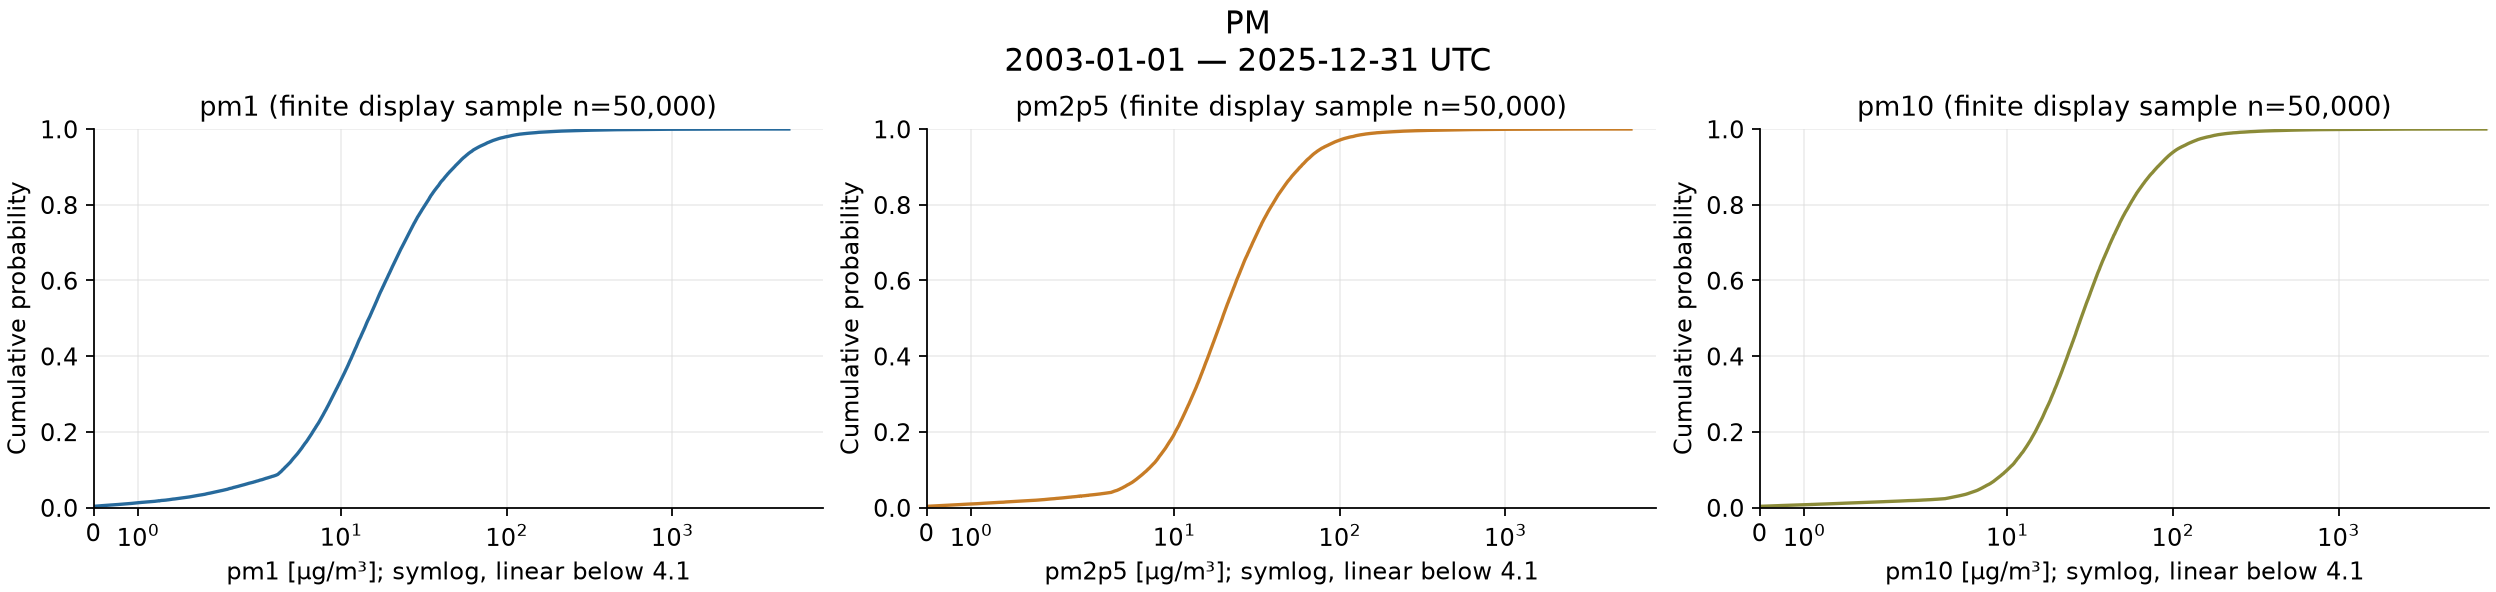

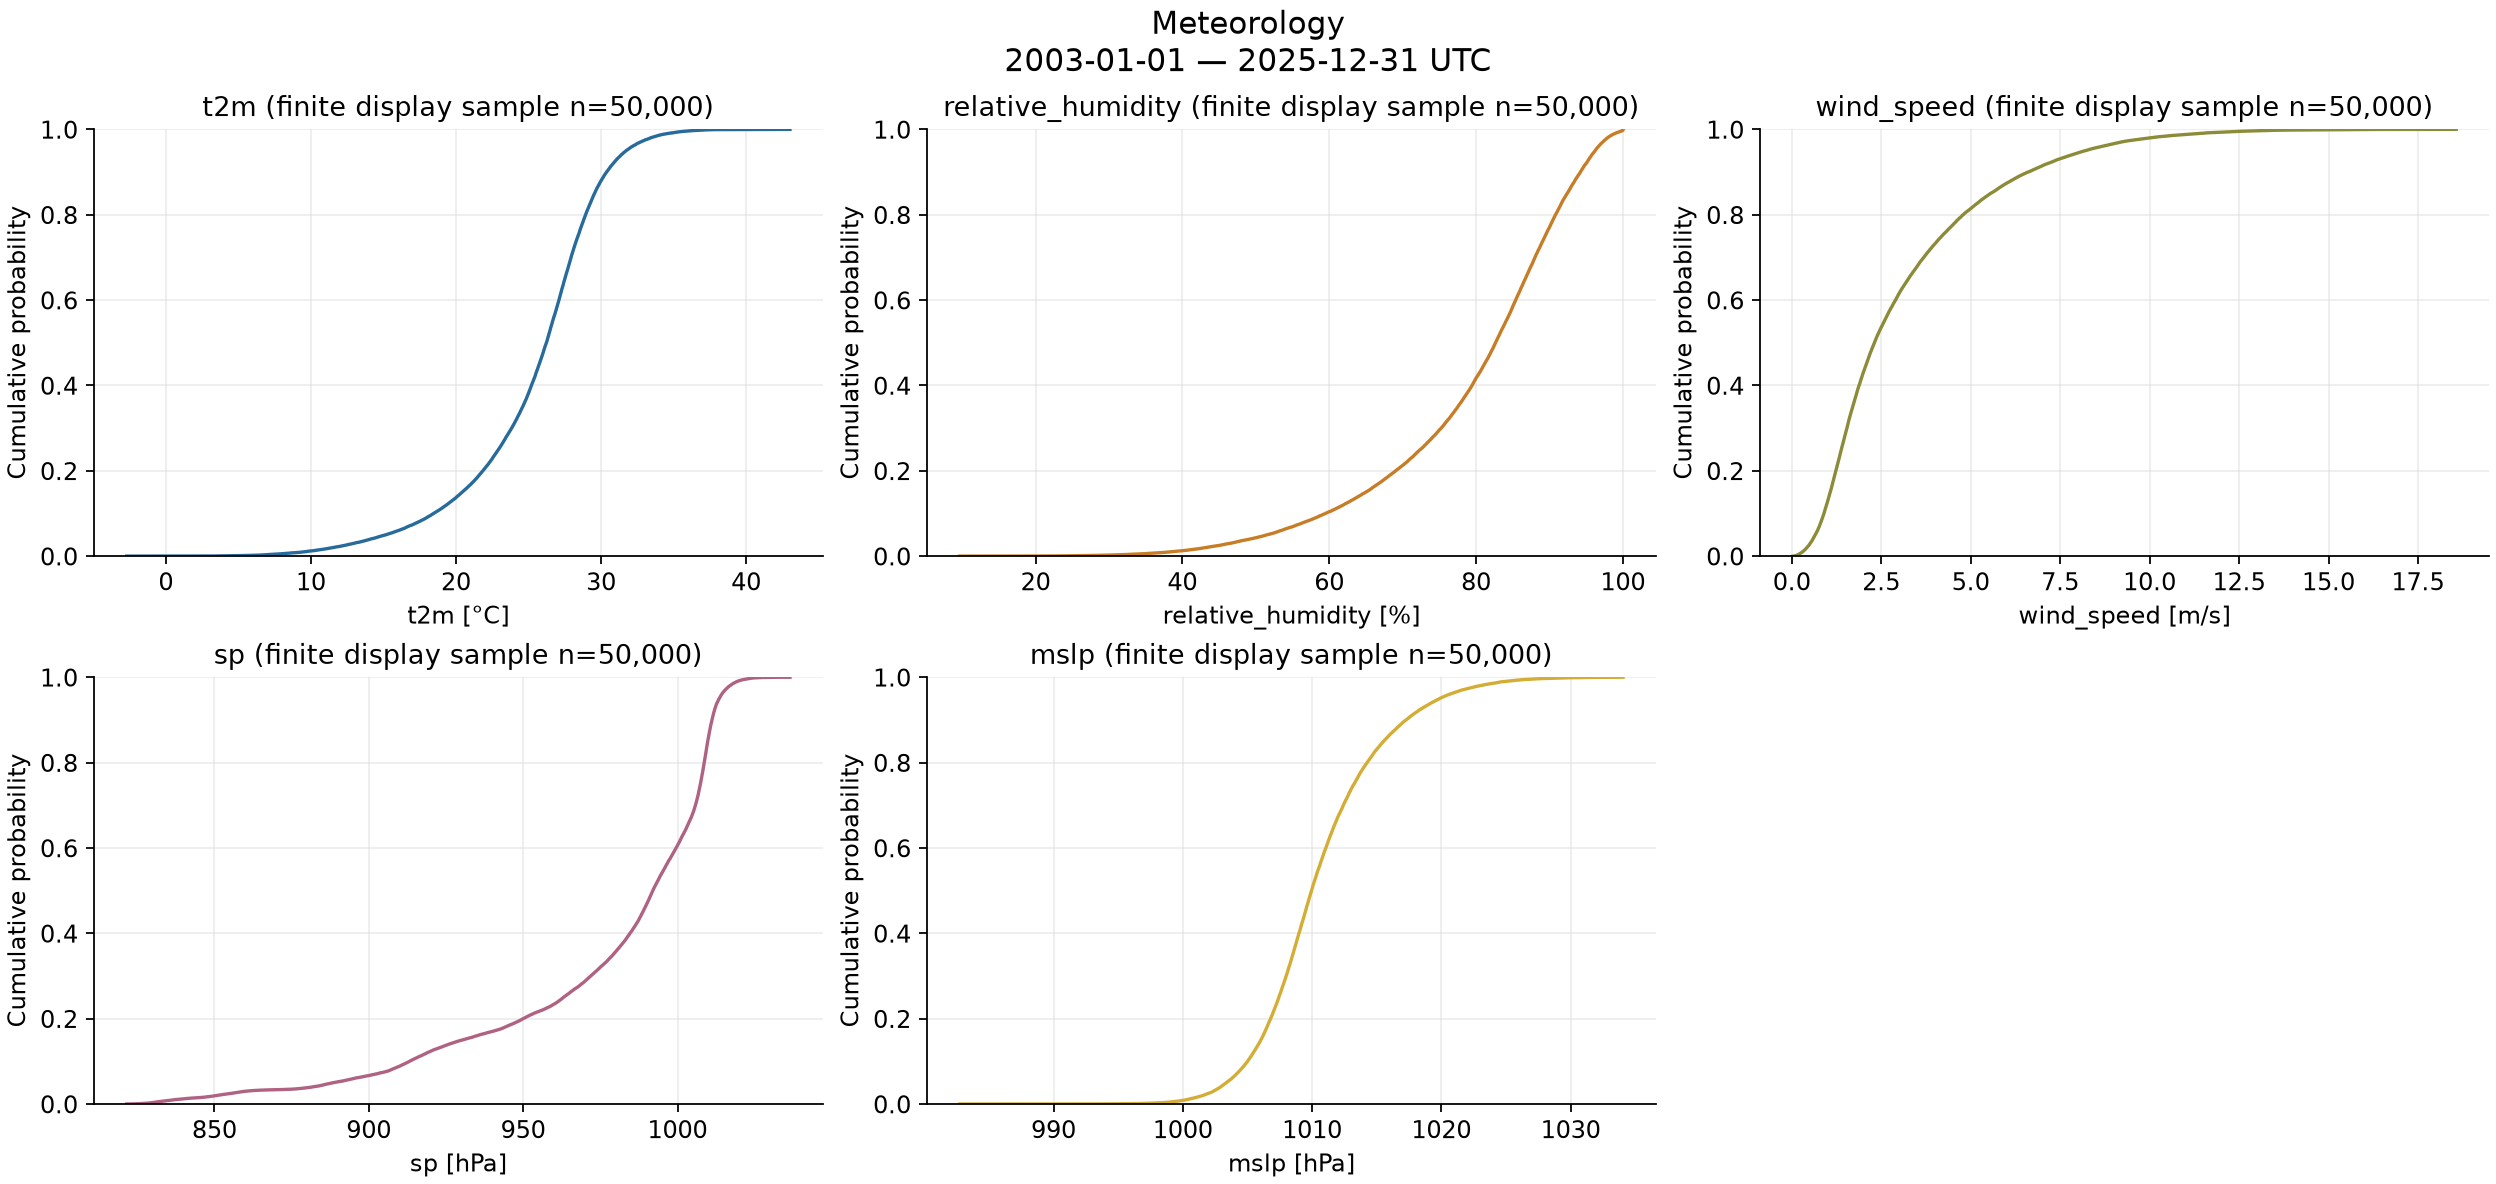

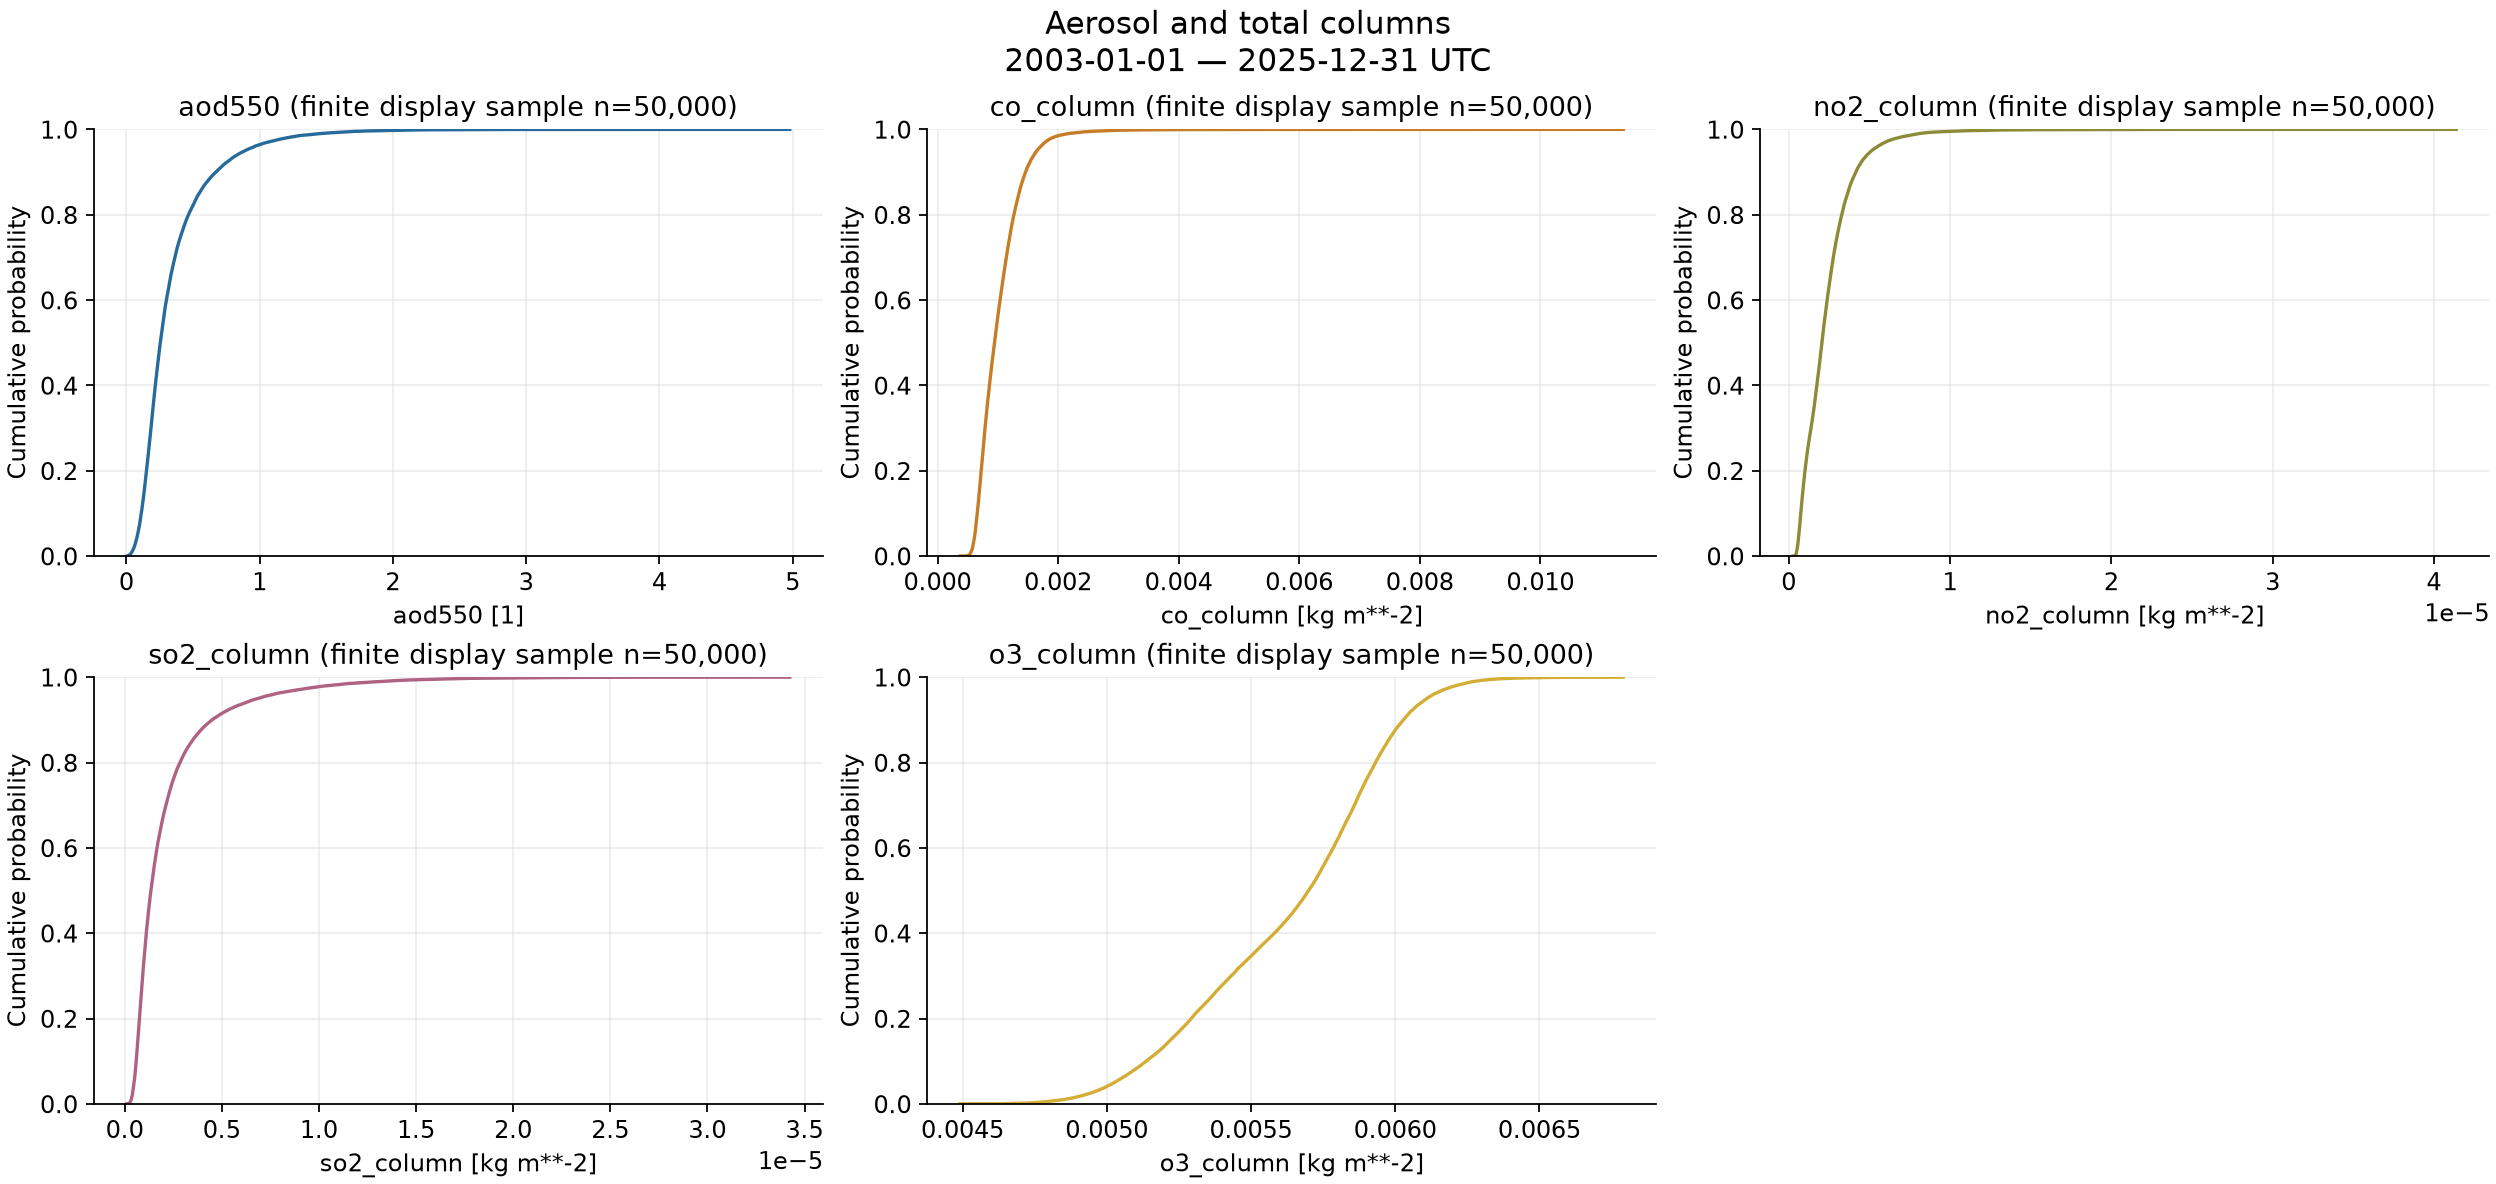

In [12]:
show_figures(run.distributions())

In [13]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('distribution'))))

**Finding:**

pm2p5: khoảng P5–P95 [4.785, 78.95] µg/m³; thống kê percentile chính xác trên các điểm grid × time hữu hạn, ECDF chỉ dùng mẫu có seed=42.

## 9. Temporal patterns

**Question:** Annual means, monthly seasonality và local-hour cycle khác nhau thế nào?

**Why this analysis:** Aggregate trước để tránh raw plot 67k timestamp; UTC gốc không bị đổi.

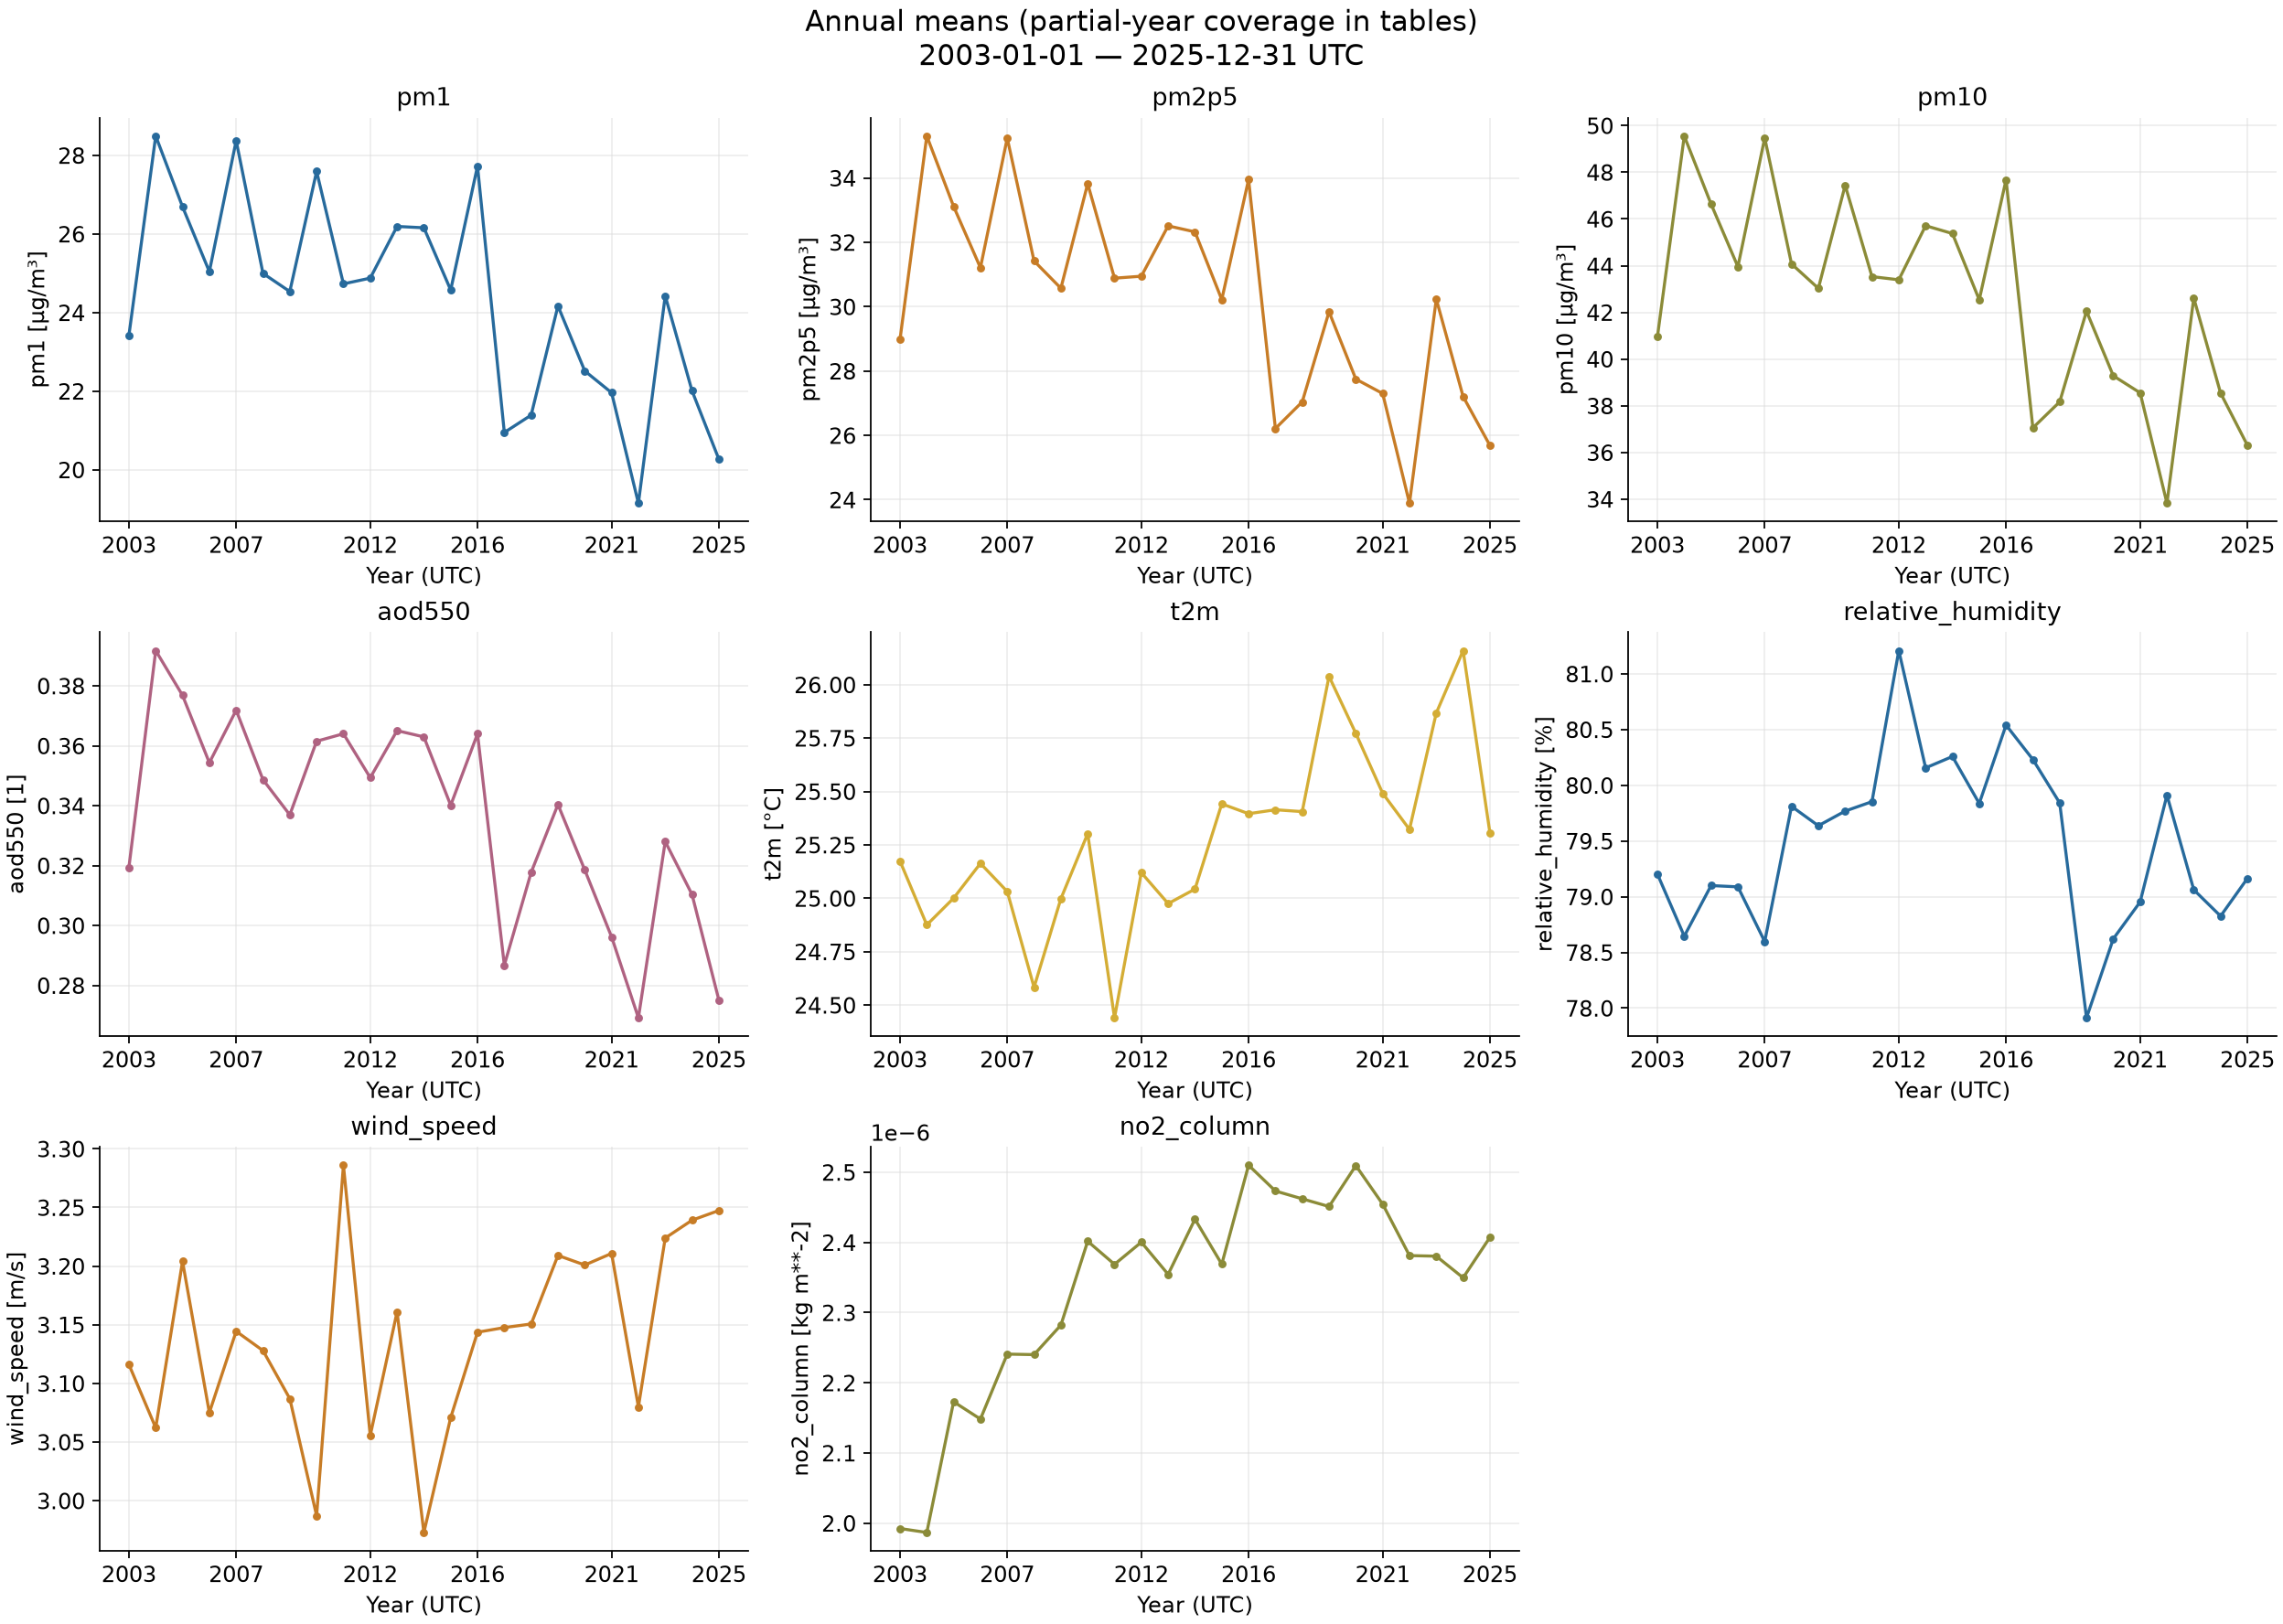

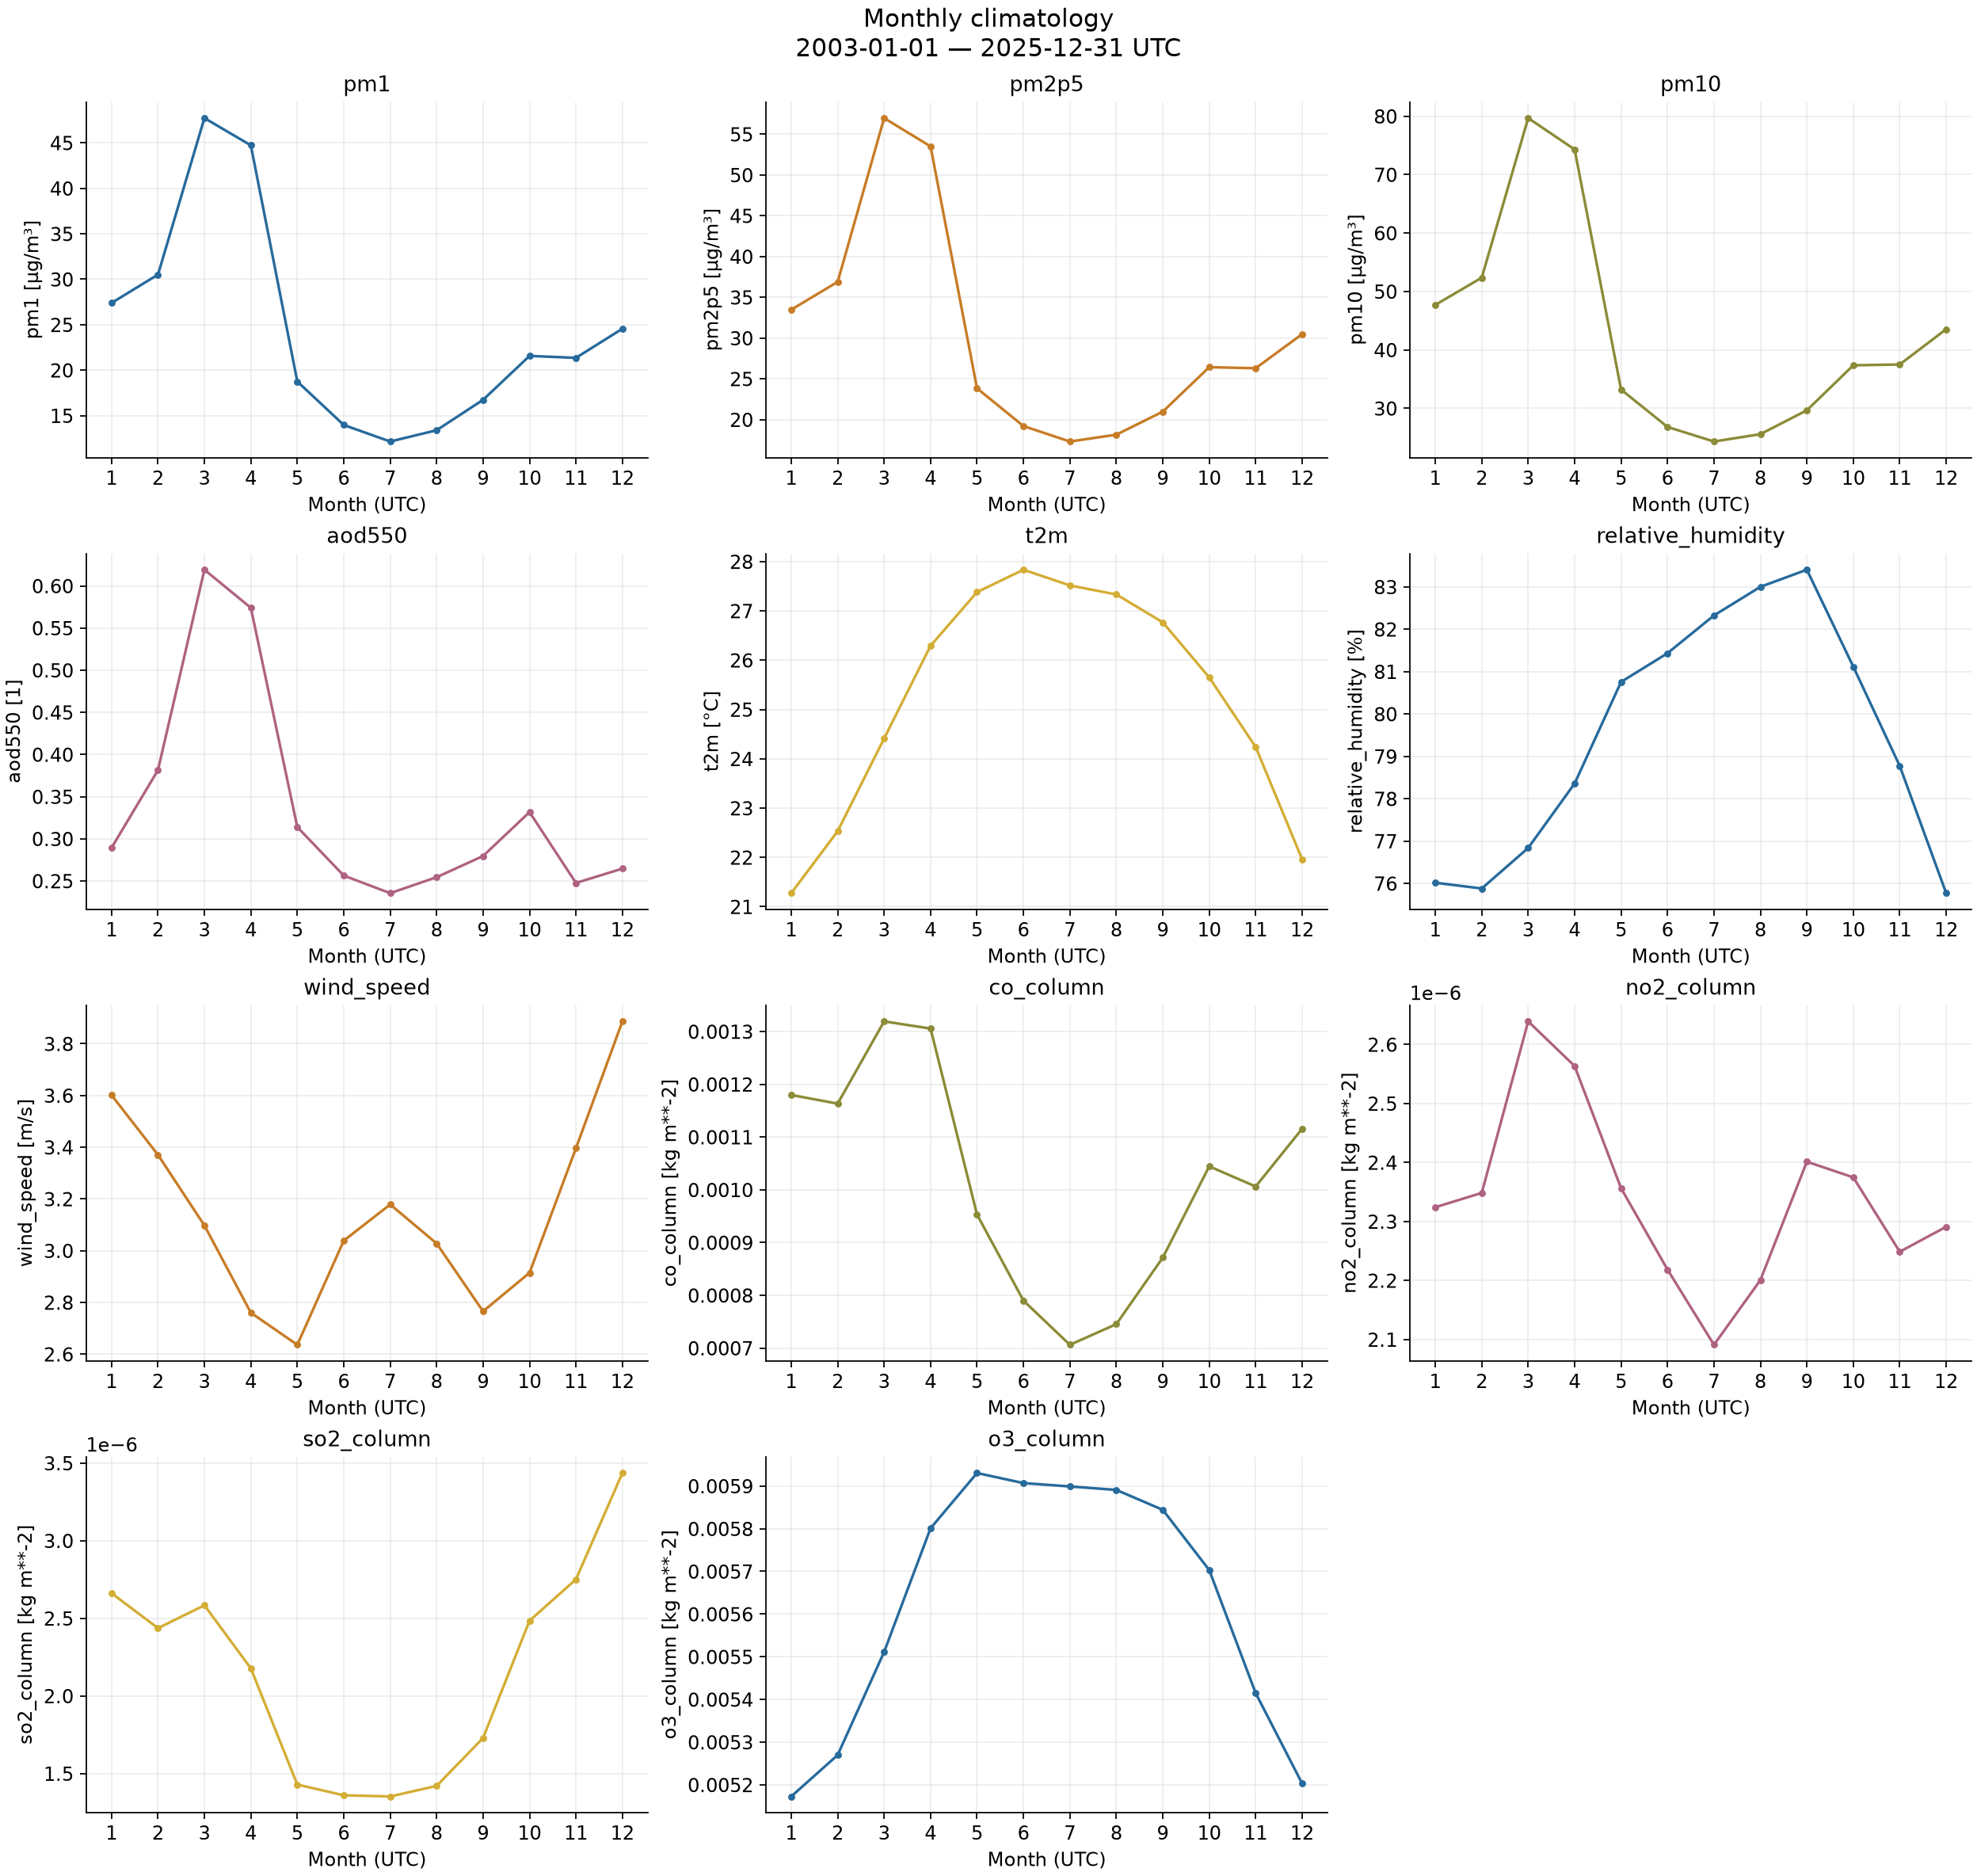

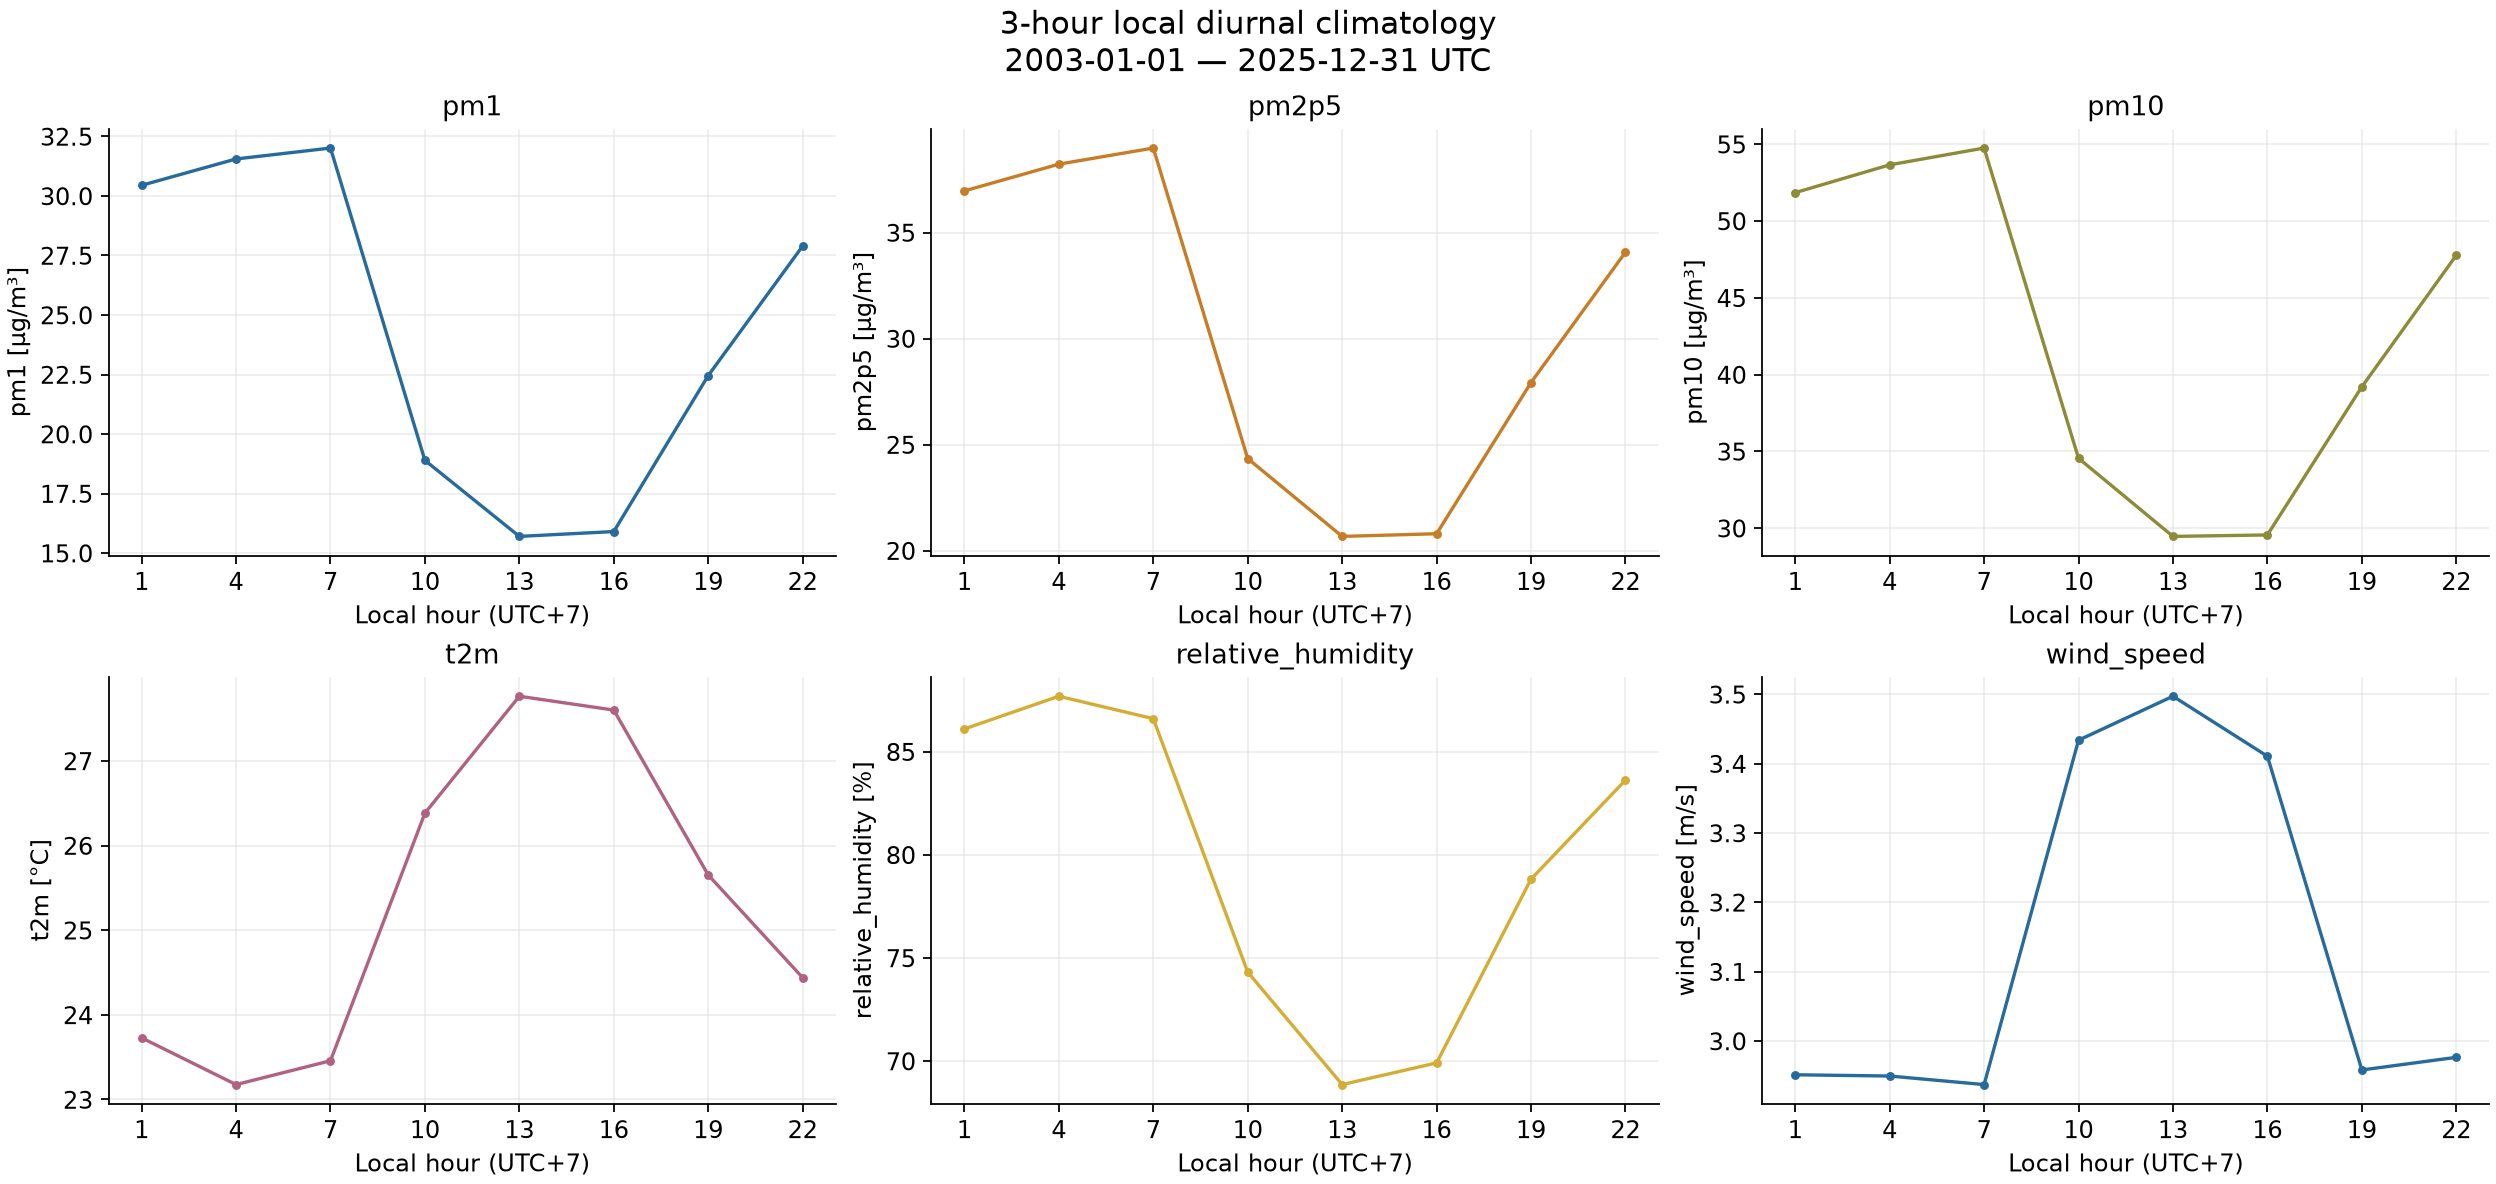

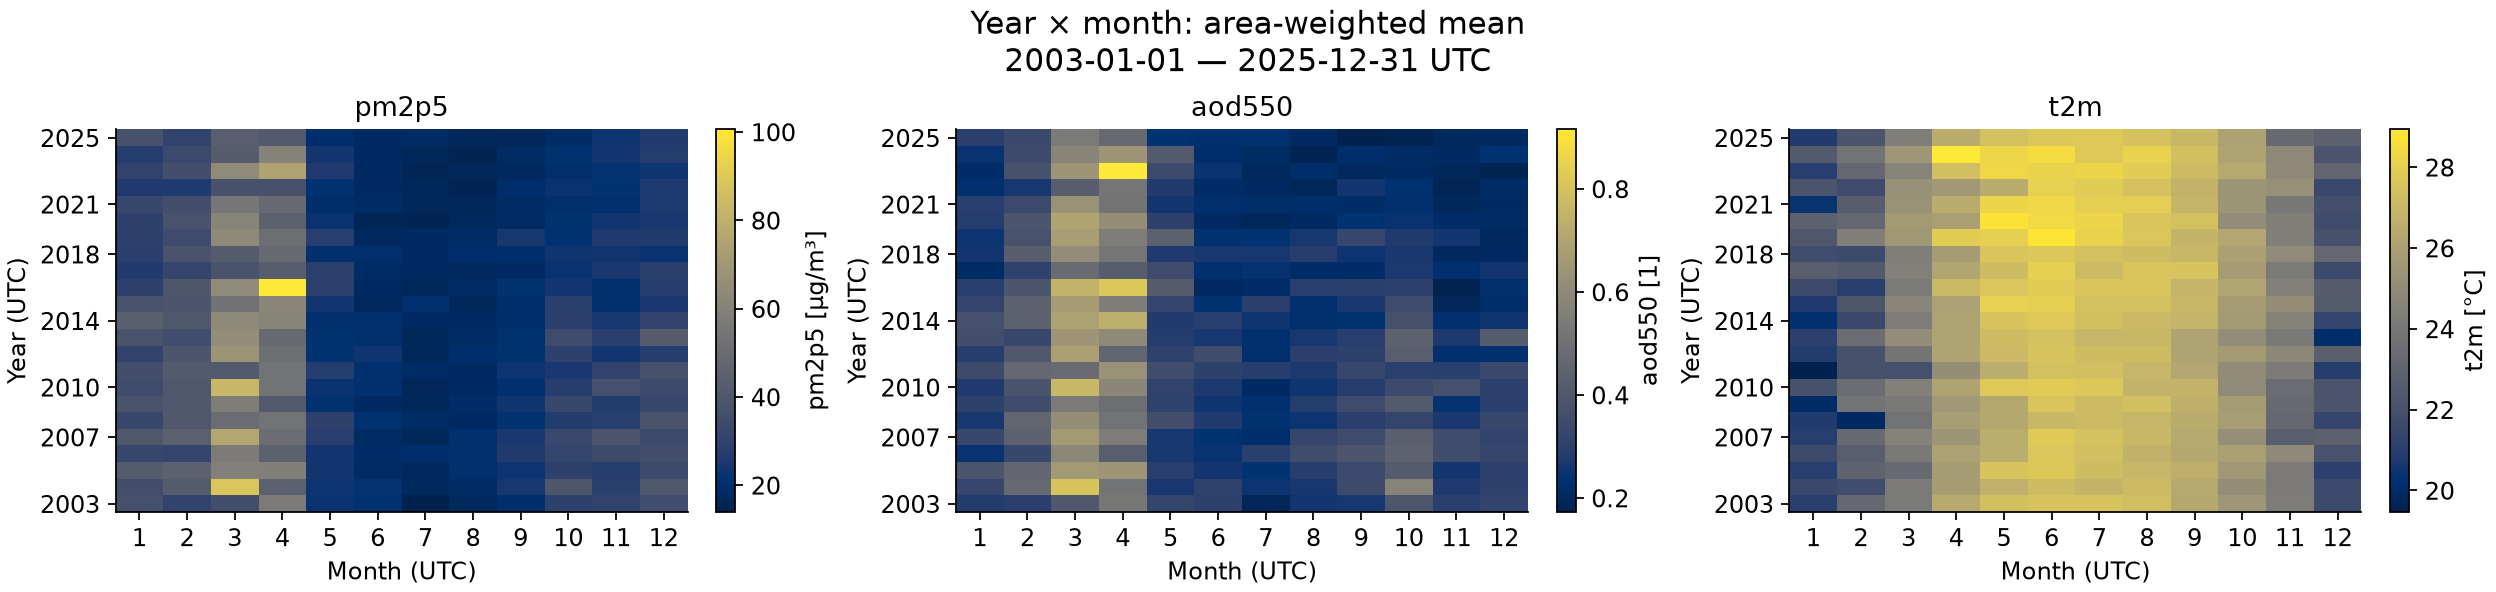

In [14]:
show_figures(run.temporal())

In [15]:
# Annual finite regional timestep counts identify incomplete years; no zero-filling observations.
display(pd.concat({name: agg['annual_count'].to_series()
                   for name, agg in run.aggregations.items()}, axis=1)
        if run.aggregations else pd.DataFrame())


,pm1,pm2p5,pm10,u10,v10,t2m,d2m,sp,mslp,aod550,co_column,no2_column,so2_column,o3_column,wind_speed,relative_humidity,pm1_pm2p5_ratio,pm2p5_pm10_ratio
time,,,,,,,,,,,,,,,,,,
2003-01-01,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920
2004-01-01,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928
2005-01-01,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920
2006-01-01,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920
2007-01-01,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920
2008-01-01,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928,2928
2009-01-01,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920
2010-01-01,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920
2011-01-01,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920,2920


In [16]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('temporal'))))

**Finding:**

pm2p5: climatology trung bình vùng cao nhất tháng 3 (56.97 µg/m³), thấp nhất tháng 7 (17.31 µg/m³).

pm2p5: climatology tại các giờ được quan sát cao nhất lúc 07:00 UTC+7 (38.98 µg/m³). Dữ liệu 3 giờ không xác định được peak giữa các giờ này.

## 10. Spatial patterns

**Question:** Mean và P95 tập trung ở ô nào của native grid?

**Why this analysis:** Tính mean/median/std/P95 dọc time từng ô; không flatten trước aggregation.

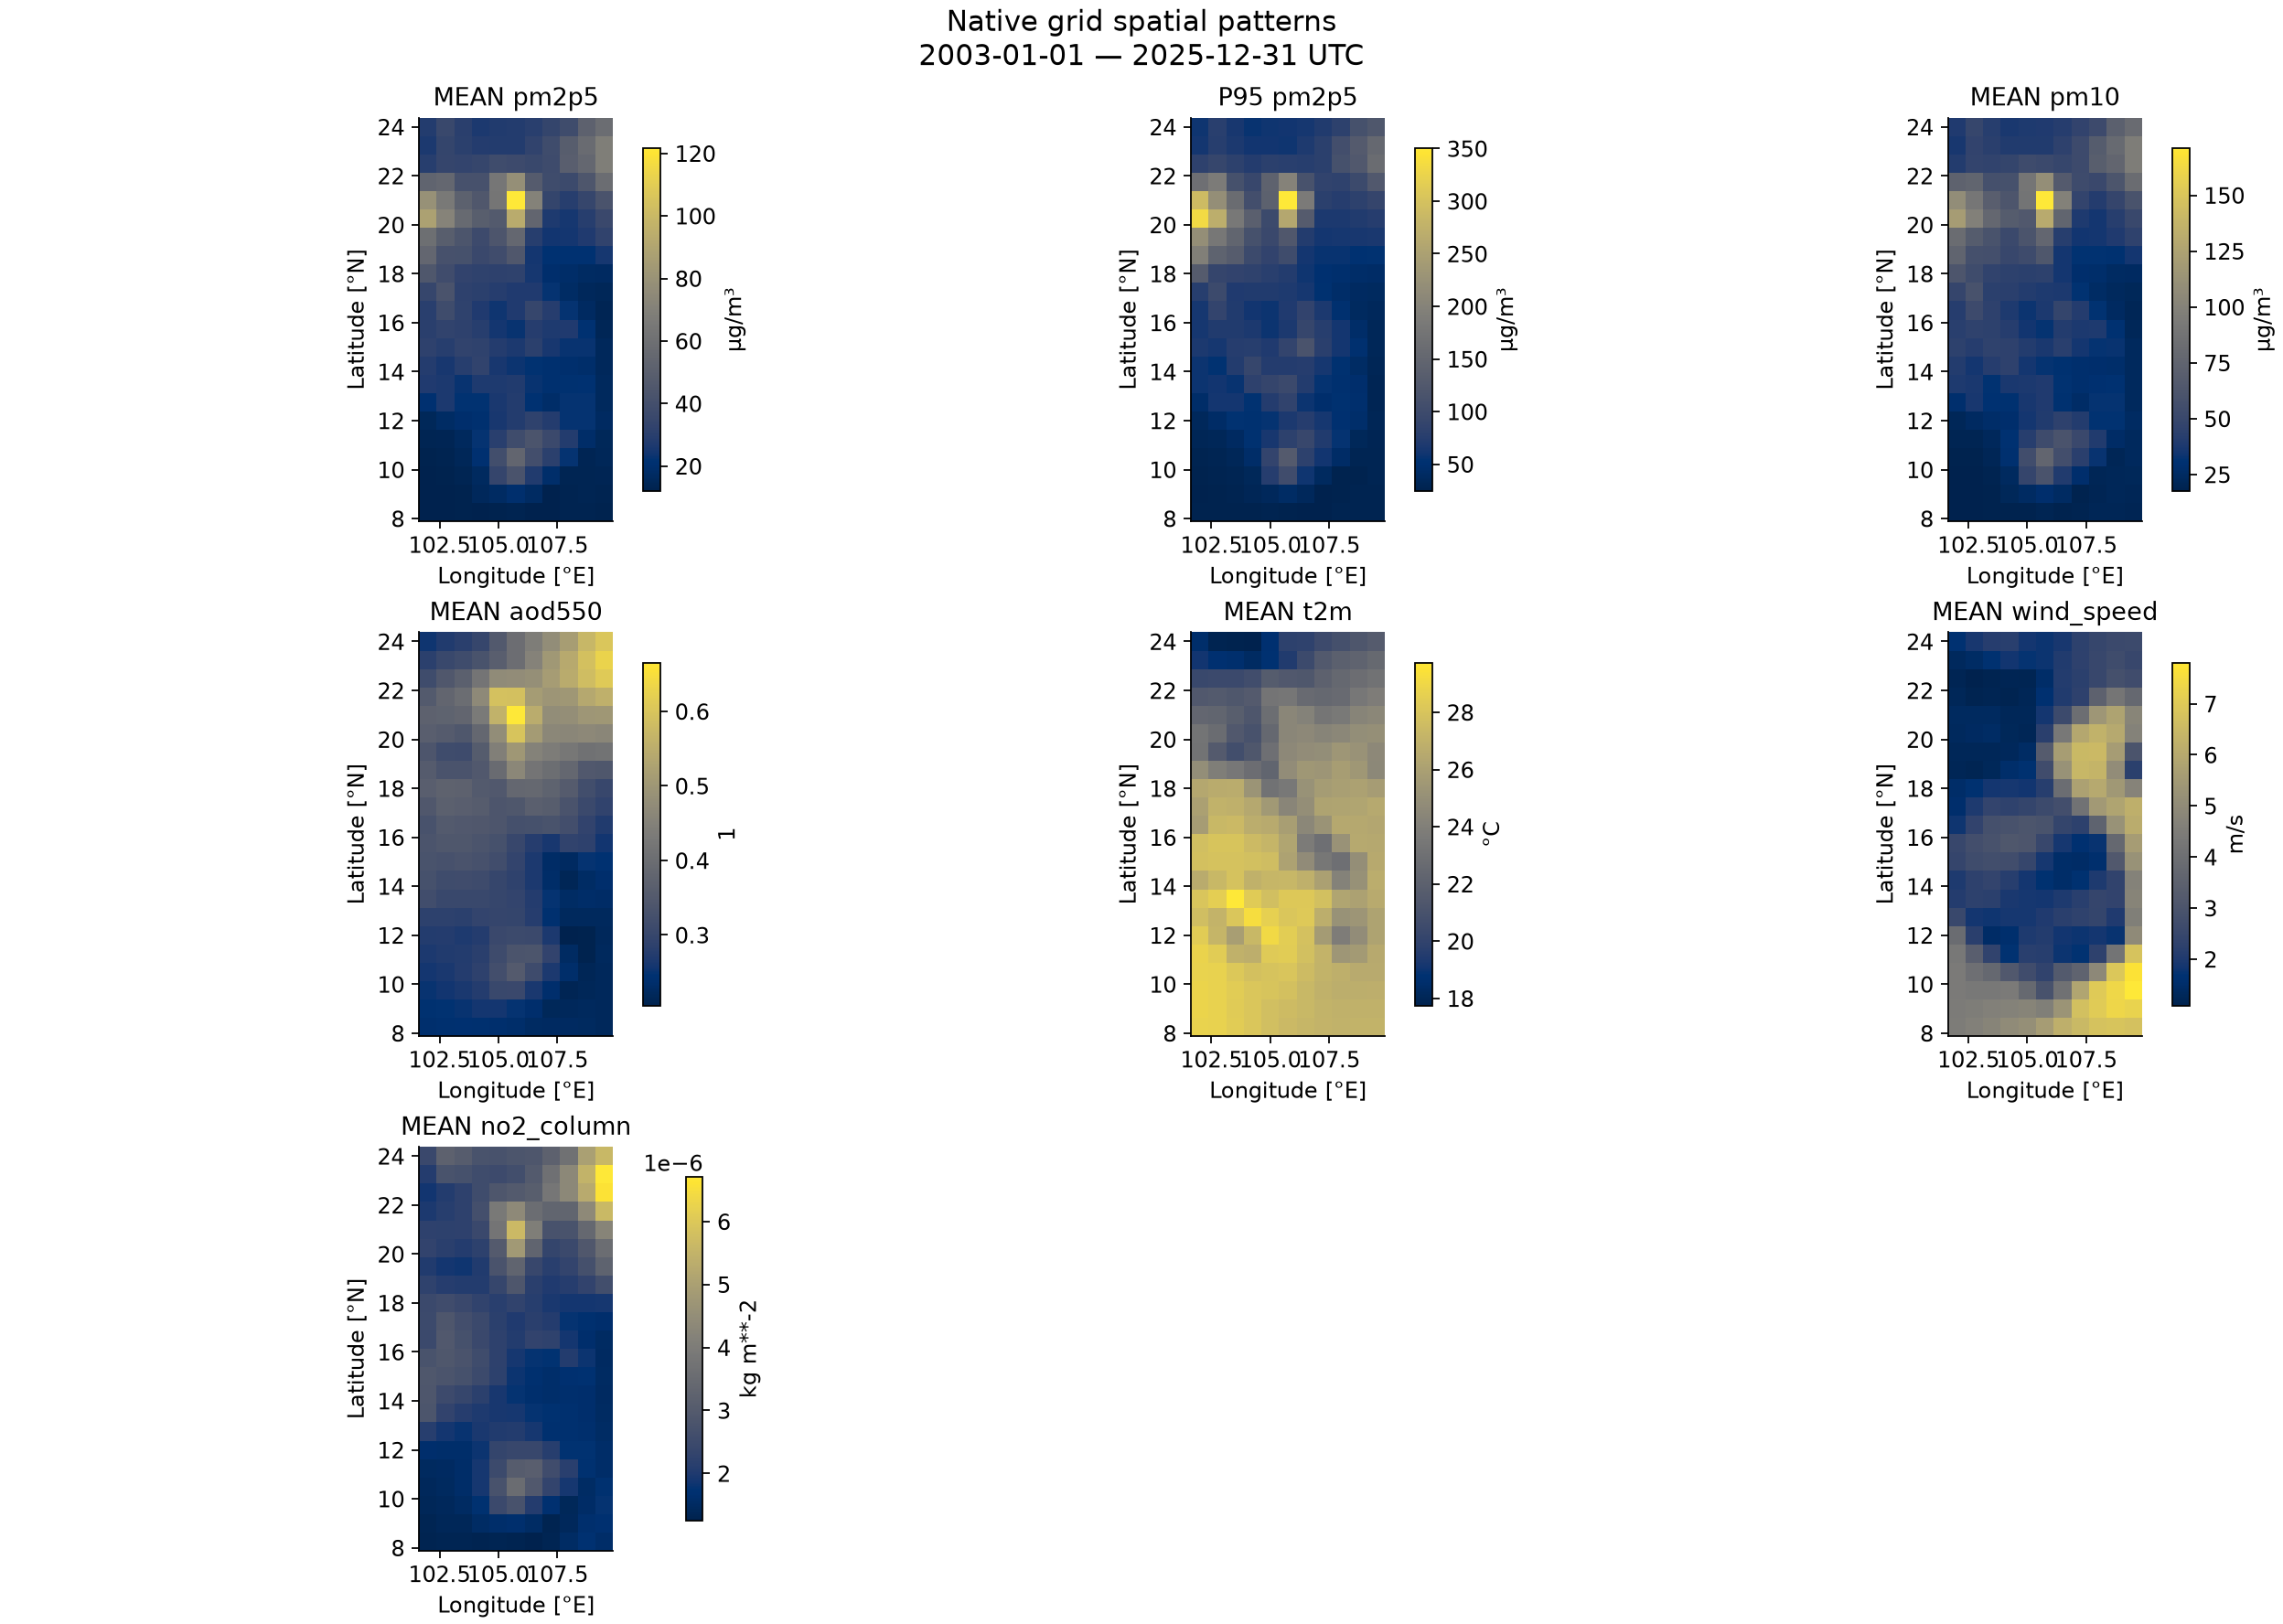

In [17]:
show_figures(run.spatial_patterns())

In [18]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('spatial'))))

**Finding:**

Ô có mean pm2p5 cao nhất trong bounding box: 21.000°N, 105.750°E (121.7 µg/m³). Đây là ô grid, chưa được xác định là địa điểm hay hotspot trong ranh giới Việt Nam.

## 11. Spatial trends

**Question:** Annual grid mean thay đổi tuyến tính theo năm như thế nào?

**Why this analysis:** Dùng ≥3 năm có coverage ≥95%, tránh fit regression raw 3-hourly hoặc diễn giải năm thiếu như năm đầy đủ.

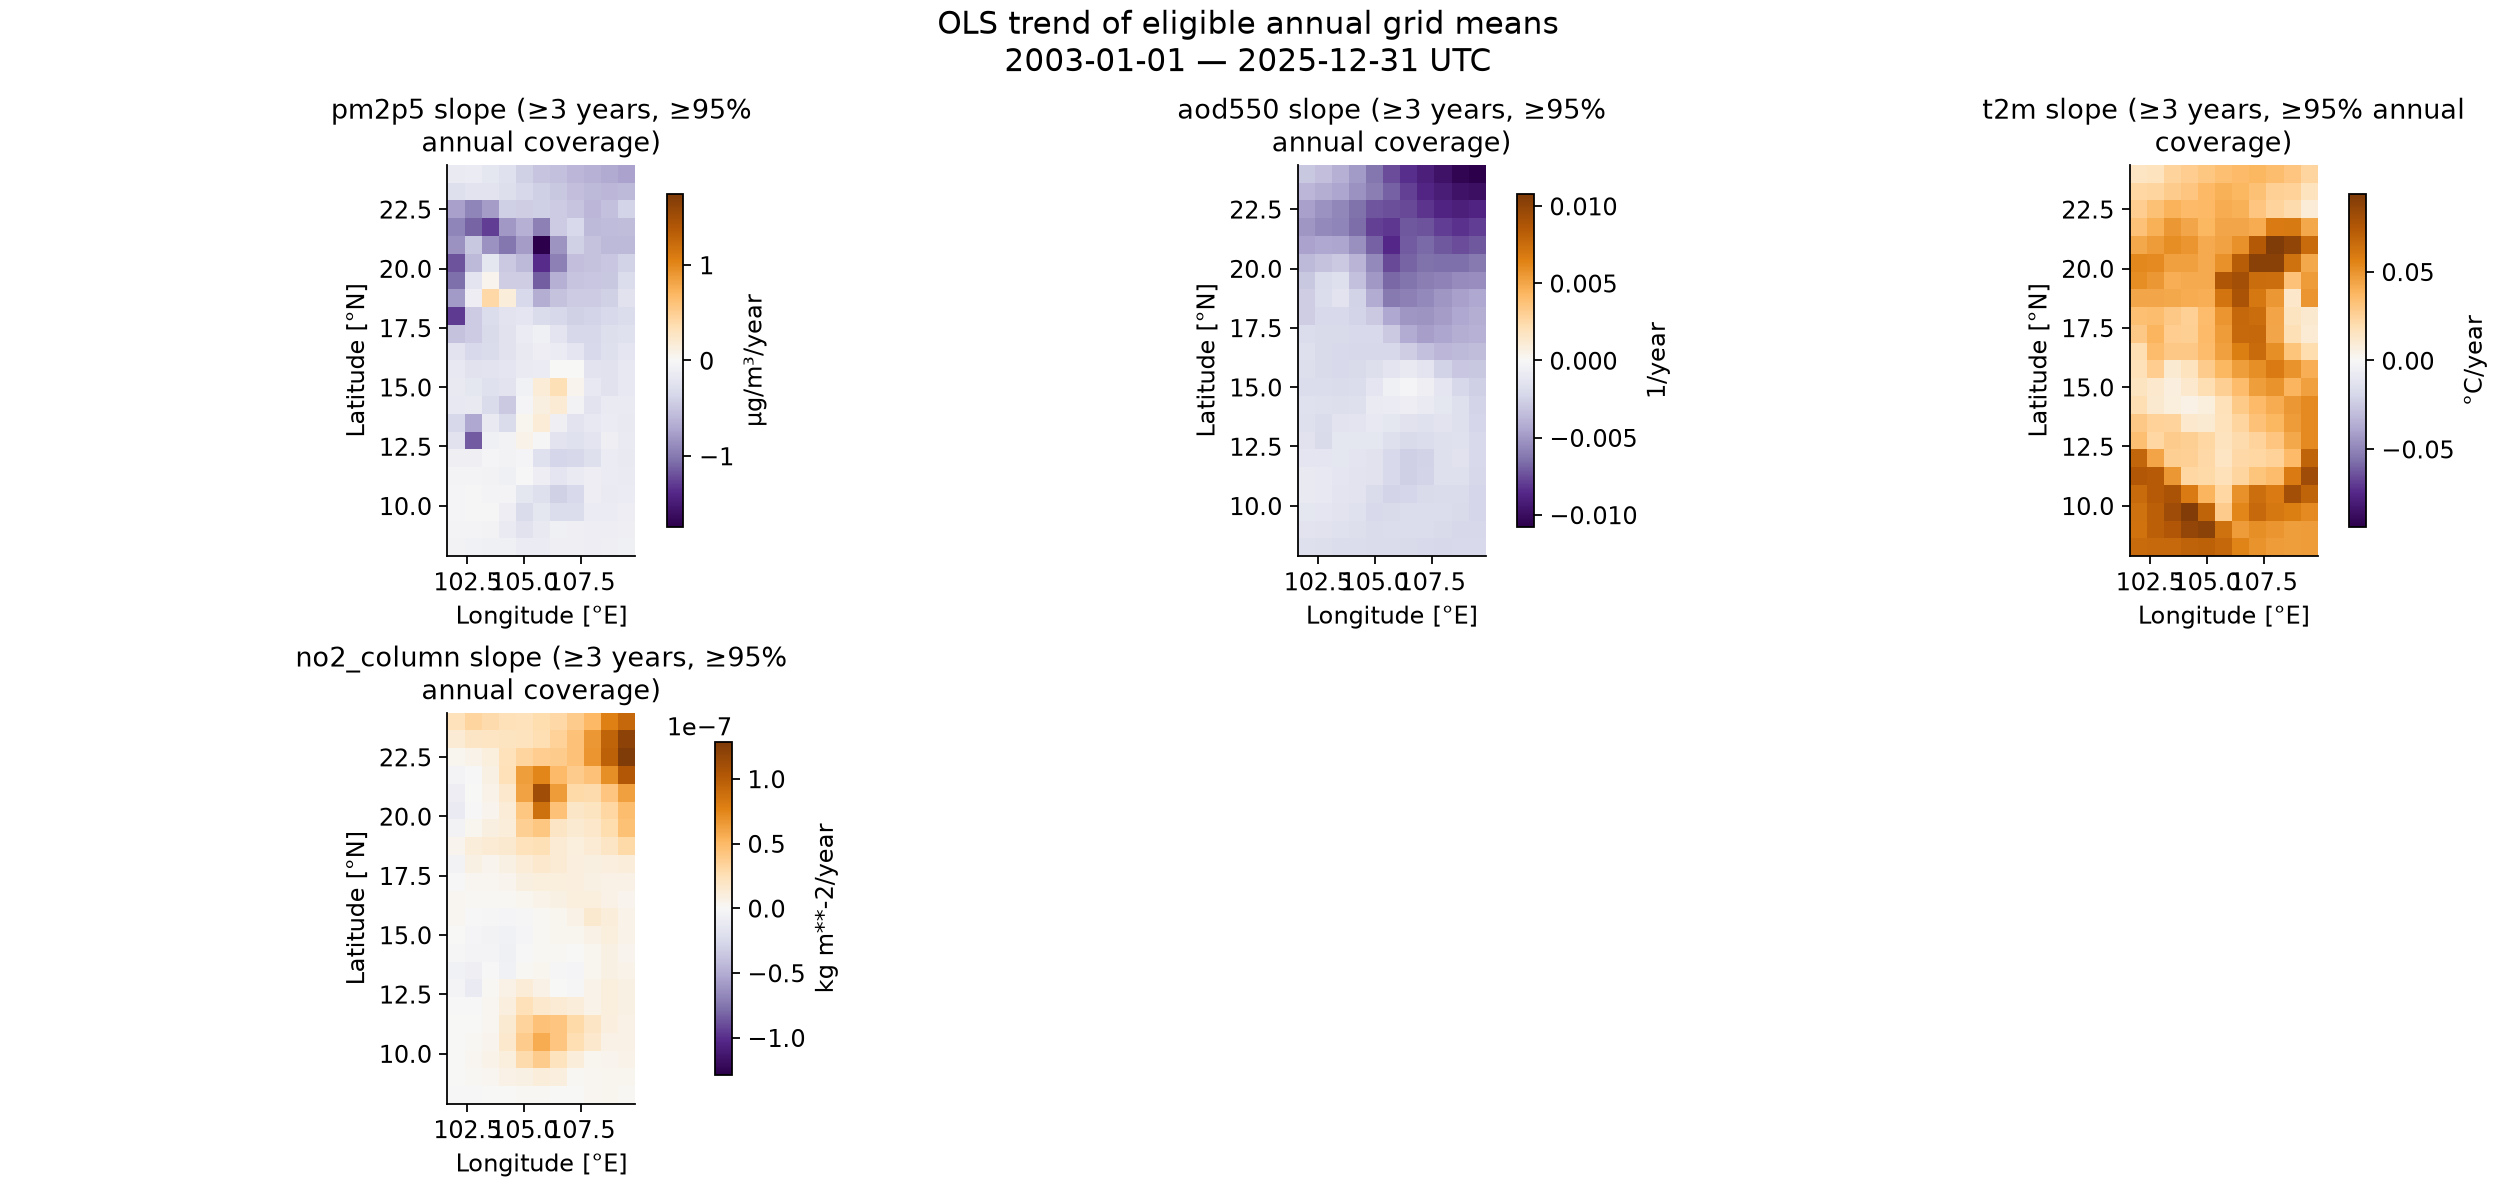

In [19]:
show_figures(run.spatial_trends())

In [20]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('trend'))))

**Finding:**

pm2p5: slope annual-grid trong khoảng [-1.742, 0.4184] µg/m³/year, ít nhất 3 năm có coverage ≥95%; chưa kiểm định ý nghĩa thống kê.

aod550: slope annual-grid trong khoảng [-0.01077, -0.0001783] 1/year, ít nhất 3 năm có coverage ≥95%; chưa kiểm định ý nghĩa thống kê.

t2m: slope annual-grid trong khoảng [0.004631, 0.09378] °C/year, ít nhất 3 năm có coverage ≥95%; chưa kiểm định ý nghĩa thống kê.

no2_column: slope annual-grid trong khoảng [-1.147e-08, 1.285e-07] kg m**-2/year, ít nhất 3 năm có coverage ≥95%; chưa kiểm định ý nghĩa thống kê.

## 12. Cross-variable relationships

**Question:** PM fractions, meteorology, AOD và total columns liên hệ ra sao?

**Why this analysis:** Dùng daily area-weighted means, exact grid/time alignment và paired-day denominator; không train model.

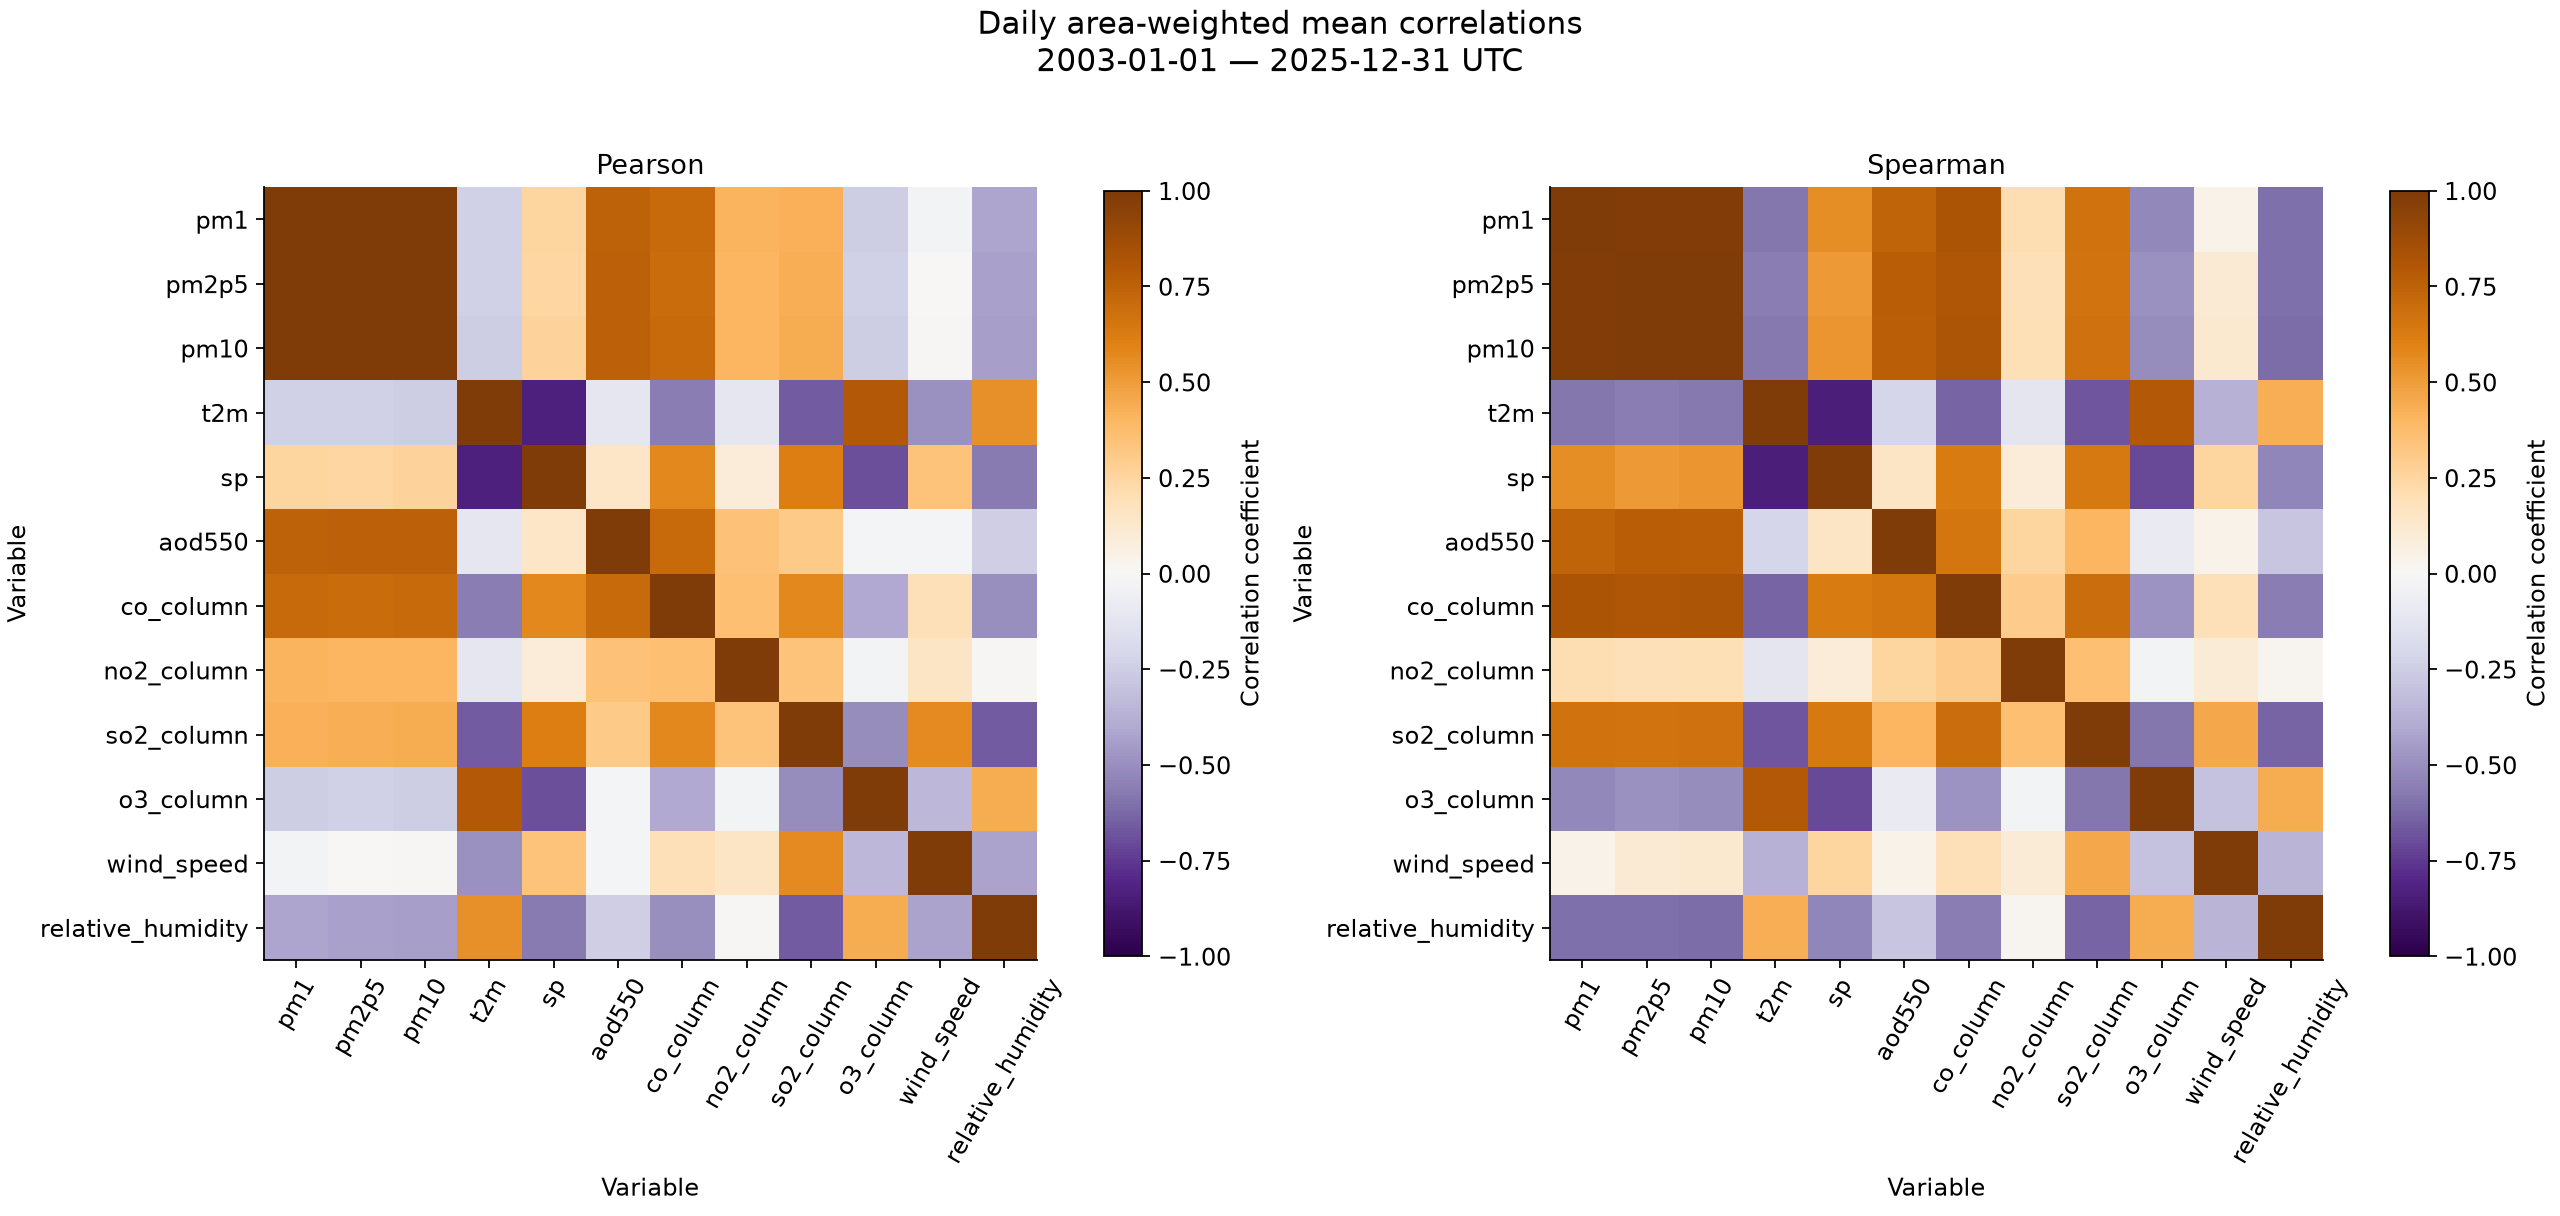

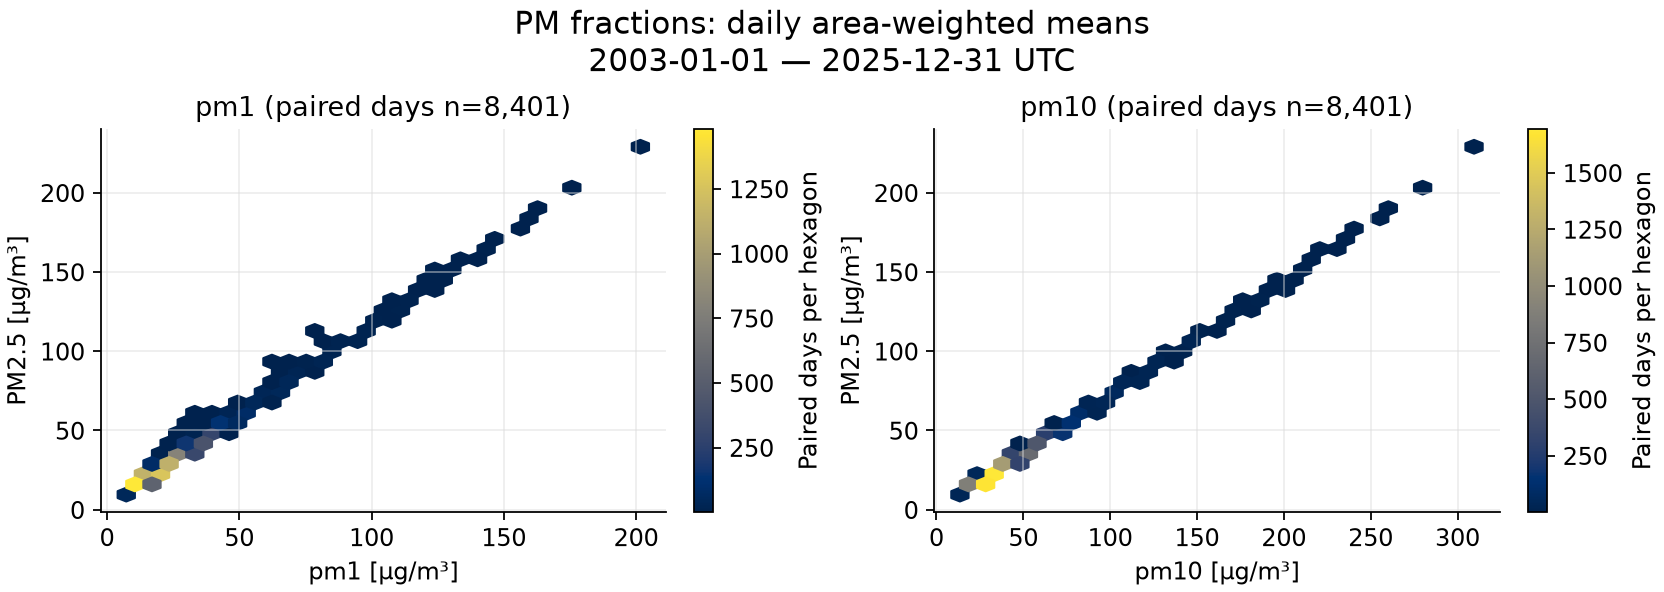

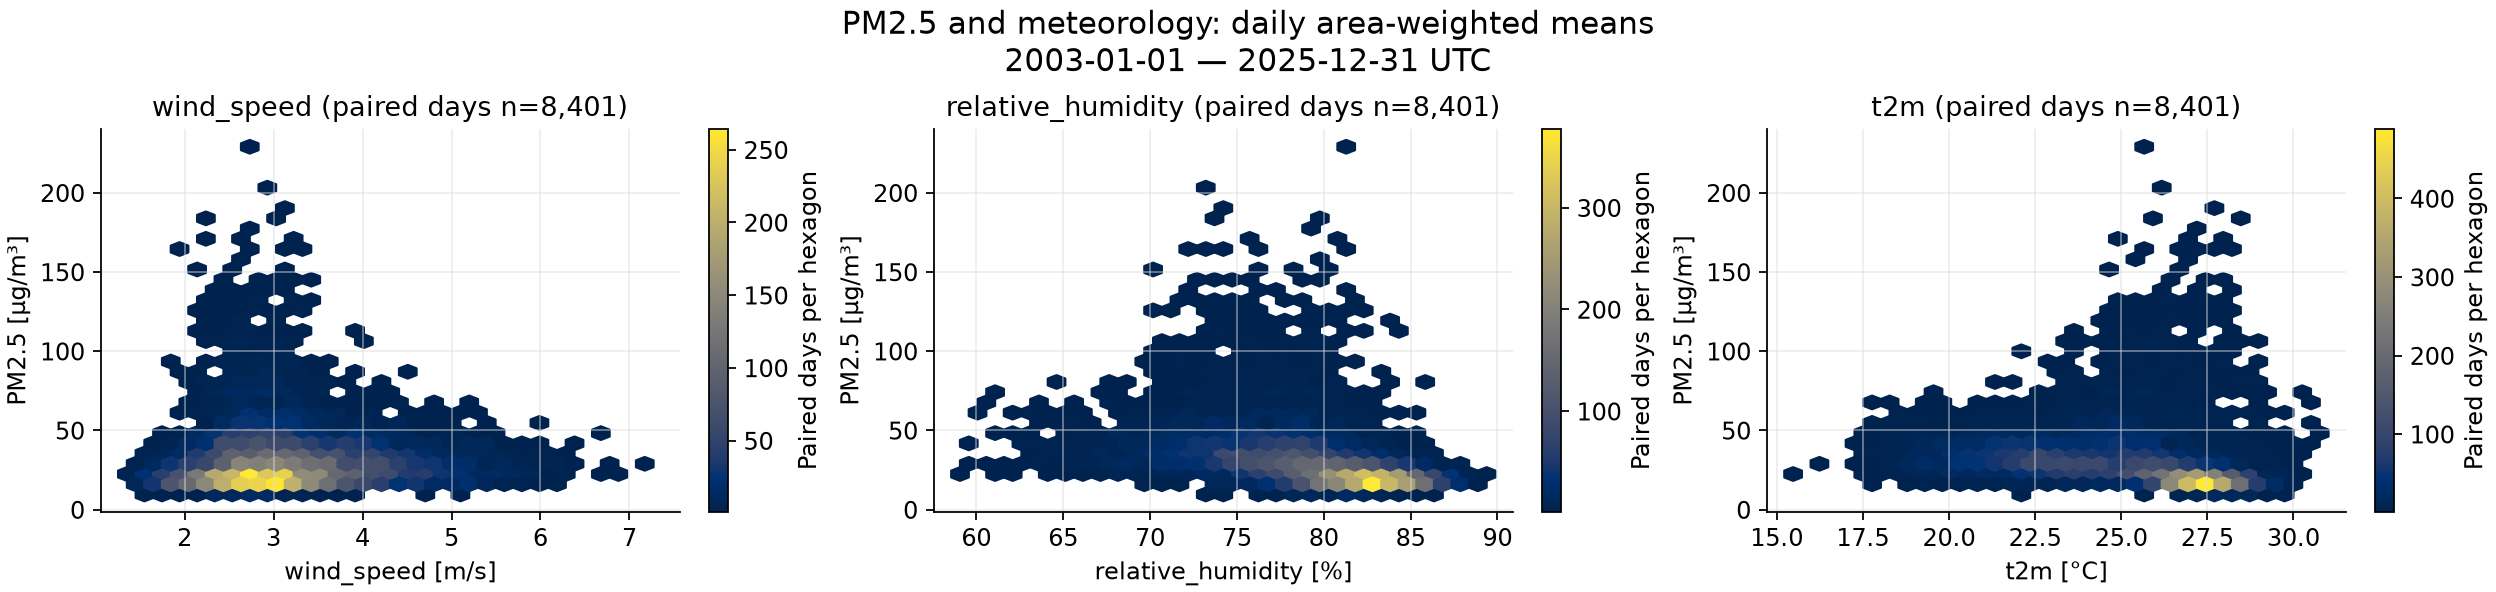

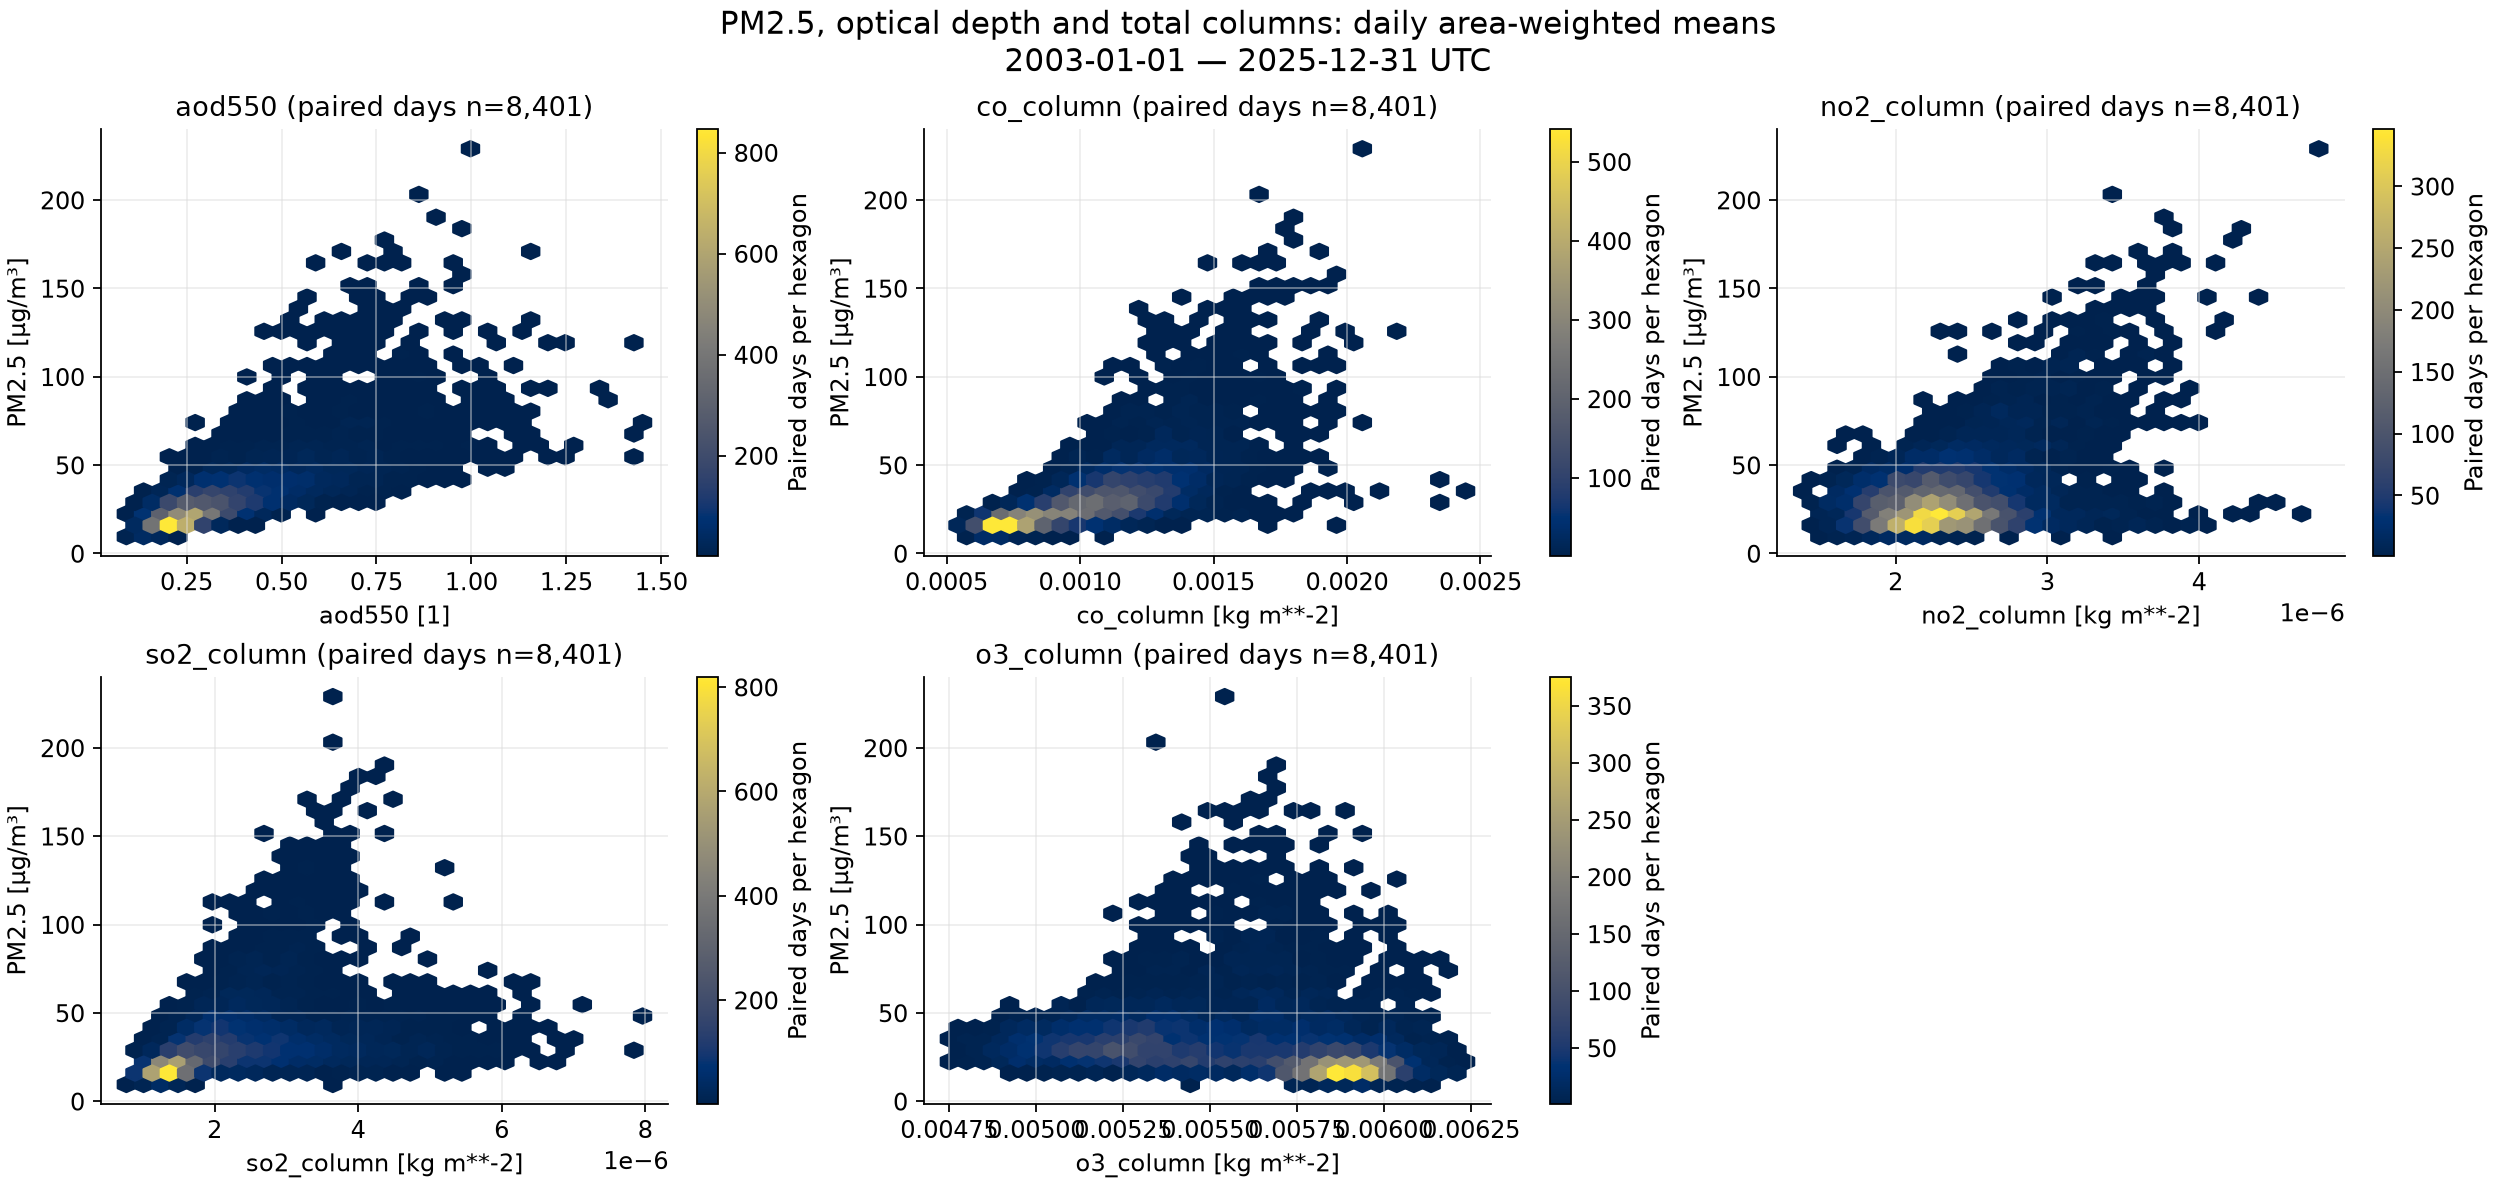

In [21]:
show_figures(run.relationships())

In [22]:
display(run.seasonal)
display(run.pair_counts)
display(Markdown('PM2.5 = near-surface mass concentration; AOD = column-integrated optical property. '
                 'CO/NO2/SO2/O3 = total columns với unit từ GRIB. '
                 'Correlation không phải quan hệ 1:1 hoặc causal relationship. '
                 'PM ratios dùng NaN khi mẫu số ≤0/nonfinite.'))


,season,paired_days,pearson,spearman
0,DJF,2076,0.700742,0.724390
1,MAM,2116,0.686441,0.832134
2,JJA,2116,0.860084,0.839828
3,SON,2093,0.785212,0.735093


,pm1,pm2p5,pm10,u10,v10,t2m,d2m,sp,mslp,aod550,co_column,no2_column,so2_column,o3_column,wind_speed,relative_humidity,pm1_pm2p5_ratio,pm2p5_pm10_ratio
pm1,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
pm2p5,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
pm10,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
u10,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
v10,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
t2m,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
d2m,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
sp,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
mslp,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401
aod550,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401,8401


PM2.5 = near-surface mass concentration; AOD = column-integrated optical property. CO/NO2/SO2/O3 = total columns với unit từ GRIB. Correlation không phải quan hệ 1:1 hoặc causal relationship. PM ratios dùng NaN khi mẫu số ≤0/nonfinite.

In [23]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('relationships'))))

**Finding:**

Daily mean PM2.5 với pm1: Pearson=0.997, Spearman=0.987, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với pm10: Pearson=1.000, Spearman=0.999, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với wind_speed: Pearson=0.003, Spearman=0.104, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với relative_humidity: Pearson=-0.430, Spearman=-0.605, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với t2m: Pearson=-0.238, Spearman=-0.558, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với aod550: Pearson=0.758, Spearman=0.773, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với co_column: Pearson=0.702, Spearman=0.807, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với no2_column: Pearson=0.403, Spearman=0.192, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với so2_column: Pearson=0.431, Spearman=0.660, 8,401 ngày ghép hữu hạn; association mô tả.

Daily mean PM2.5 với o3_column: Pearson=-0.239, Spearman=-0.489, 8,401 ngày ghép hữu hạn; association mô tả.

pm1_pm2p5_ratio: mean=0.7602, median=0.8124; mẫu số ≤0 hoặc không hữu hạn tạo NaN (51,342 missing ratio, bao gồm missing đầu vào).

pm2p5_pm10_ratio: mean=0.7014, median=0.7094; mẫu số ≤0 hoặc không hữu hạn tạo NaN (51,340 missing ratio, bao gồm missing đầu vào).

## 13. Extreme PM2.5

**Question:** Pooled P95/P99 bị vượt khi nào, ở đâu và đi kèm điều kiện nào?

**Why this analysis:** Định nghĩa extreme data-driven, đếm timestep có ≥1 ô vượt ngưỡng và so sánh co-located finite points.

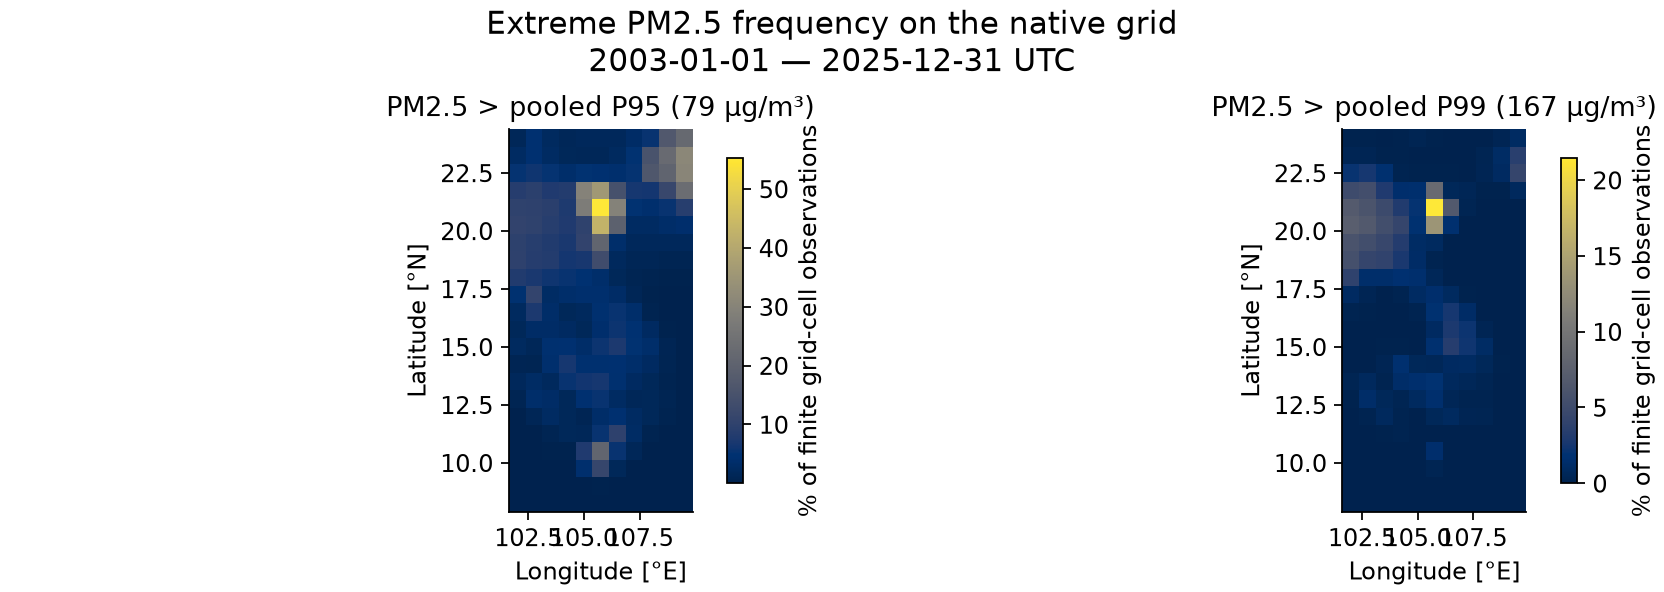

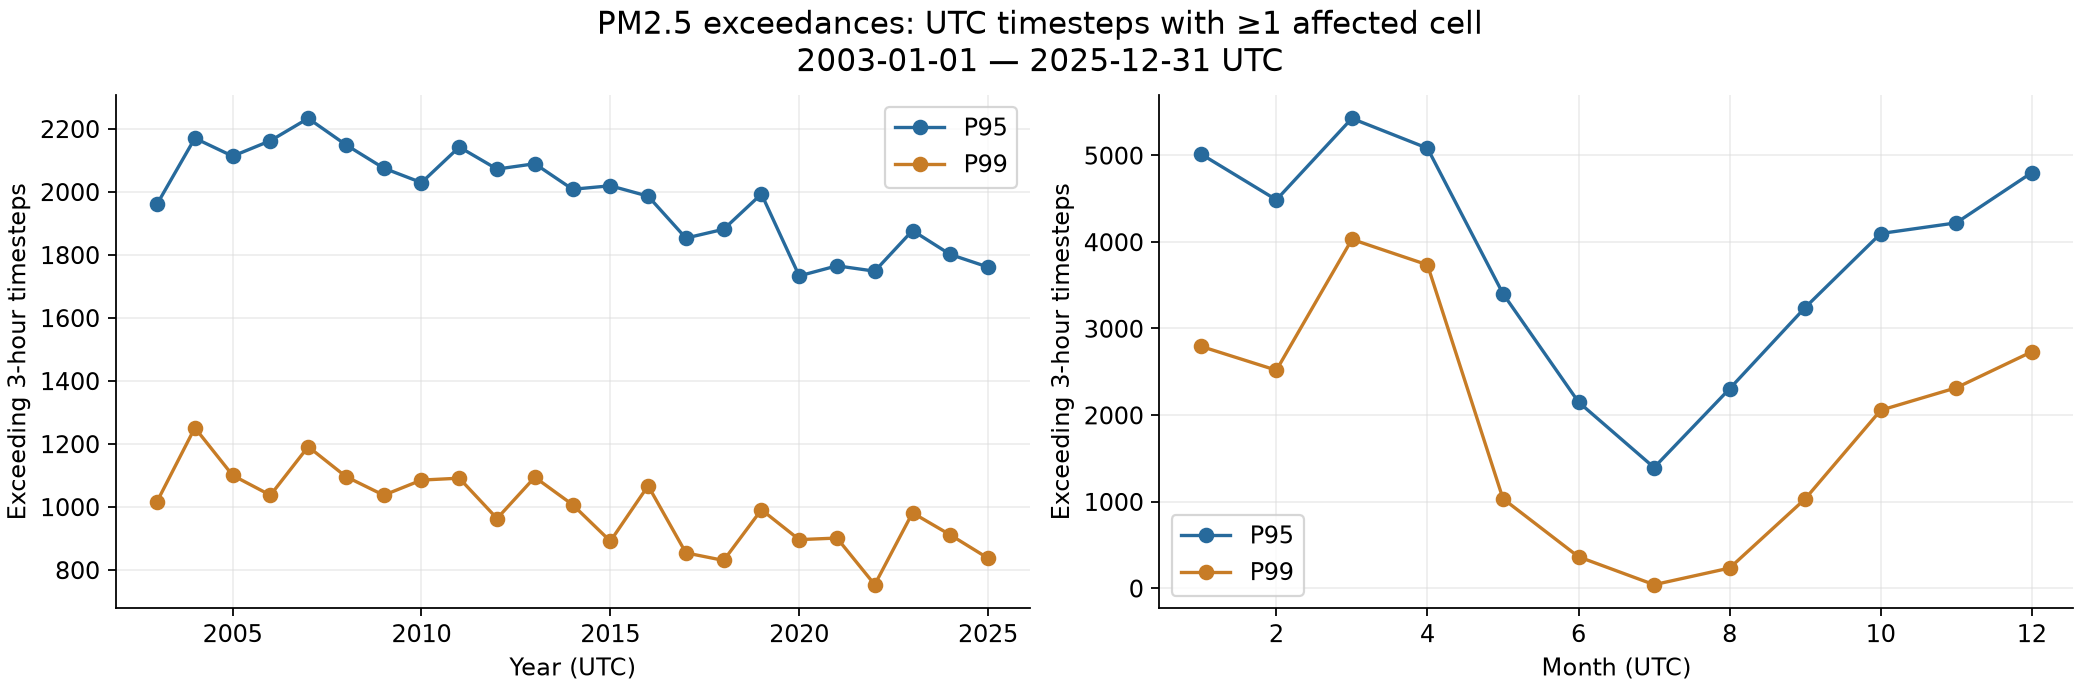

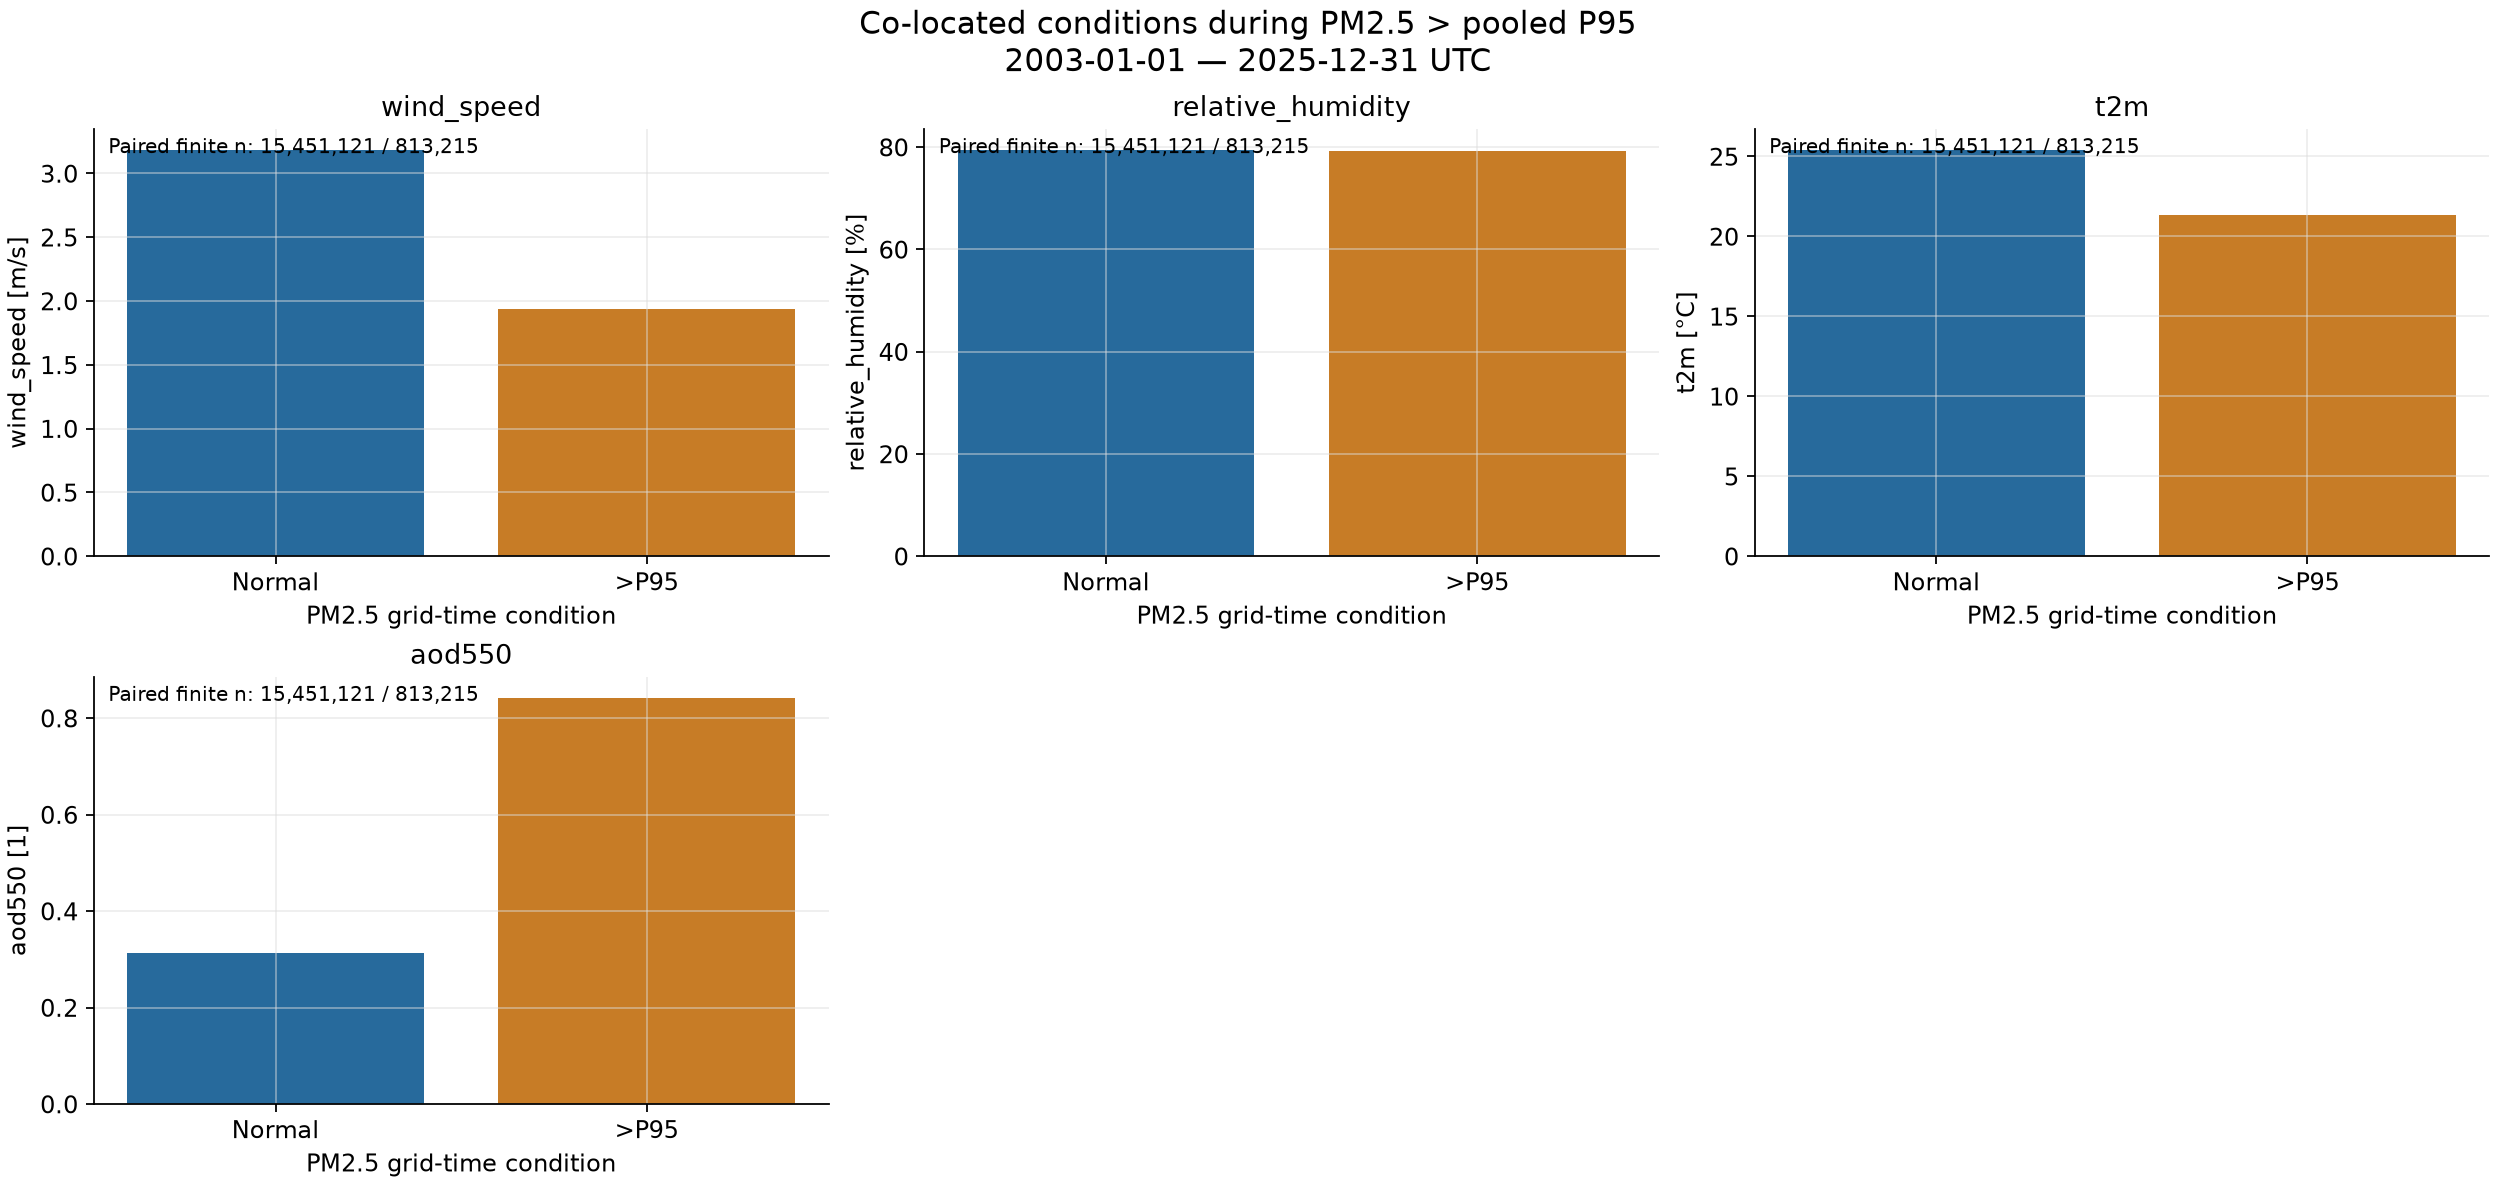

,variable,unit,normal_mean,extreme_mean,normal_count,extreme_count
0,wind_speed,m/s,3.185772,1.934427,15451121.0,813215.0
1,relative_humidity,%,79.487122,79.201424,15451121.0,813215.0
2,t2m,°C,25.421654,21.317055,15451121.0,813215.0
3,aod550,1,0.312247,0.842649,15451121.0,813215.0


,p95_timestep_count,p99_timestep_count,finite_timestep_count,p95_timestep_pct,p99_timestep_pct
year,,,,,
2003,1961,1017,2920,67.157534,34.828767
2004,2170,1251,2928,74.112022,42.725410
2005,2113,1100,2920,72.363014,37.671233
2006,2162,1037,2920,74.041096,35.513699
2007,2233,1191,2920,76.472603,40.787671
2008,2149,1096,2928,73.394809,37.431694
2009,2075,1037,2920,71.061644,35.513699
2010,2029,1085,2920,69.486301,37.157534
2011,2142,1091,2920,73.356164,37.363014


In [24]:
show_figures(run.extreme_pm25())
display(run.extreme_comparison)
display(run.extreme_yearly)


In [25]:
display(Markdown('**Finding:**\n\n' + '\n\n'.join(run.findings('extreme'))))

**Finding:**

Ngưỡng pooled PM2.5: P95=78.95, P99=167.2 µg/m³. Tổng timestamp có ít nhất một ô vượt ngưỡng: 45,620 (>P95) và 22,881 (>P99).

wind_speed: mean tại điểm normal=3.186, tại điểm PM2.5 >P95=1.934 m/s; so sánh đồng vị trí/thời điểm, chưa điều chỉnh mùa hoặc địa lý.

relative_humidity: mean tại điểm normal=79.49, tại điểm PM2.5 >P95=79.2 %; so sánh đồng vị trí/thời điểm, chưa điều chỉnh mùa hoặc địa lý.

t2m: mean tại điểm normal=25.42, tại điểm PM2.5 >P95=21.32 °C; so sánh đồng vị trí/thời điểm, chưa điều chỉnh mùa hoặc địa lý.

aod550: mean tại điểm normal=0.3122, tại điểm PM2.5 >P95=0.8426 1; so sánh đồng vị trí/thời điểm, chưa điều chỉnh mùa hoặc địa lý.

## 14. Modeling implications

**Question:** Những dependency, redundancy và leakage risk nào cần kiểm tra trước modeling?

**Why this analysis:** EDA chỉ đề xuất feature để validation, không khẳng định feature hữu ích qua association đơn giản.

In [26]:
autocorrelation = pd.DataFrame([
    {'variable': name, 'daily_lag1_autocorrelation': series.autocorr(1),
     'daily_lag7_autocorrelation': series.autocorr(7), 'finite_days': series.notna().sum()}
    for name, series in run.daily.items()])
display(autocorrelation)
run._save_table('daily_autocorrelation', autocorrelation)
display(Markdown('**Finding:** Autocorrelation trong bảng trên được tính từ chuỗi daily mean; '
                 'dùng temporal/geographic holdout để kiểm tra ảnh hưởng phụ thuộc thời gian và không gian. '
                 'Fit ngưỡng percentile/climatology chỉ từ training period; không dùng target PM fractions '
                 'đồng thời hoặc future rolling statistics nếu chúng chưa có lúc dự báo. '
                 'Feature meteorology/AOD cần validation ngoài mẫu; chưa train model.'))


,variable,daily_lag1_autocorrelation,daily_lag7_autocorrelation,finite_days
0,pm1,0.886772,0.582169,8401
1,pm2p5,0.884657,0.575383,8401
2,pm10,0.886454,0.581968,8401
3,u10,0.957726,0.764559,8401
4,v10,0.927138,0.637682,8401
5,t2m,0.972841,0.824769,8401
6,d2m,0.976251,0.818371,8401
7,sp,0.952347,0.694404,8401
8,mslp,0.952868,0.696242,8401
9,aod550,0.929773,0.662461,8401


**Finding:** Autocorrelation trong bảng trên được tính từ chuỗi daily mean; dùng temporal/geographic holdout để kiểm tra ảnh hưởng phụ thuộc thời gian và không gian. Fit ngưỡng percentile/climatology chỉ từ training period; không dùng target PM fractions đồng thời hoặc future rolling statistics nếu chúng chưa có lúc dự báo. Feature meteorology/AOD cần validation ngoài mẫu; chưa train model.

## 15. Key findings and report

**Question:** Các kết quả thực tế quan trọng nhất và artifact tái lập nằm ở đâu?

**Why this analysis:** Report lấy finding từ output đã tính, kèm missing/skipped và limitation.

In [27]:
report_path = run.write_report()
display(Markdown('**Finding:**\n\n' + '\n'.join(
    f'{i}. {text}' for i, text in enumerate(run.findings(), 1))))
display(pd.DataFrame(run.statuses))
display(Markdown(f'Report: `{report_path}`; figures: `{config.report_root / "figures"}`; '
                 f'compact tables: `{config.report_root / "tables"}`; '
                 'provenance/package versions: `eda_run_manifest.json`.'))
run.close()


**Finding:**

1. Đọc được 14/14 biến khai báo: pm1, pm2p5, pm10, u10, v10, t2m, d2m, sp, mslp, aod550, co_column, no2_column, so2_column, o3_column. Thiếu: không có. Giai đoạn quan sát: 2003-01-01 00:00:00 — 2025-12-31 21:00:00 UTC.
2. So với pm1, 14/14 biến cùng trục thời gian và 14/14 biến cùng grid theo đúng thứ tự tọa độ. Tổng timestamp thiếu so với giai đoạn cấu hình (cộng qua biến): 0; message trùng: 224.
3. Các message trùng: 224 bản có cùng decoded values/grid với bản đầu, 0 bản xung đột. Bản giống nhau dùng representation đầu của cfgrib có audit rõ ràng; bản xung đột không được dùng cho analysis liên biến.
4. pm2p5: mean=30.47, median=19.5, P95=78.95, P99=167.2, max=6903 µg/m³; 16,264,336 giá trị hữu hạn.
5. pm2p5: climatology trung bình vùng cao nhất tháng 3 (56.97 µg/m³), thấp nhất tháng 7 (17.31 µg/m³).
6. Ô có mean pm2p5 cao nhất trong bounding box: 21.000°N, 105.750°E (121.7 µg/m³). Đây là ô grid, chưa được xác định là địa điểm hay hotspot trong ranh giới Việt Nam.
7. pm2p5: slope annual-grid trong khoảng [-1.742, 0.4184] µg/m³/year, ít nhất 3 năm có coverage ≥95%; chưa kiểm định ý nghĩa thống kê.
8. Daily mean PM2.5 với pm1: Pearson=0.997, Spearman=0.987, 8,401 ngày ghép hữu hạn; association mô tả.
9. Ngưỡng pooled PM2.5: P95=78.95, P99=167.2 µg/m³. Tổng timestamp có ít nhất một ô vượt ngưỡng: 45,620 (>P95) và 22,881 (>P99).
10. 0 <= RH <= 100: 12,763/16,264,336 điểm vi phạm (0.07847%), dữ liệu giữ nguyên để xem xét.

,section,status
0,wind,computed on exactly matching grids and time axes
1,relative_humidity,computed on exactly matching grids and time axes
2,relationships,daily area-weighted means; pairwise finite day...
3,extreme_pm25,pooled finite grid-time P95/P99; strict >; a t...


Report: `D:\Data\Learning\TLCN\Code\test_data\reports\cams_eac4_eda_report.md`; figures: `D:\Data\Learning\TLCN\Code\test_data\reports\figures`; compact tables: `D:\Data\Learning\TLCN\Code\test_data\reports\tables`; provenance/package versions: `eda_run_manifest.json`.